In [1]:
from pathlib import Path
import tarfile
import shutil
import math
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

### Configuración general

In [2]:
BASE_DIR = Path.cwd()
TAR_PATH = BASE_DIR / "final_sequential_results_2026_06_04.tar.gz"

WORK_DIR = BASE_DIR / "final_results_extracted" # Carpeta temporal 
OUTPUT_DIR = BASE_DIR / "final_analysis_outputs" # Carpeta para tablas y figuras
WORK_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ALGORITHM_LABELS = {
    "random": "Random",
    "nsga3": "NSGA-III",
    "grasp": "GRASP",
    "hh_lap_v0": "HH-LAP-SIPA-Lite",
    "hh_lap_v1": "HH-LAP-SIPA-Intensive",
}

ALGORITHM_ORDER = [
    "random",
    "nsga3",
    "grasp",
    "hh_lap_v0",
    "hh_lap_v1",
]

LABEL_ORDER = [ALGORITHM_LABELS[a] for a in ALGORITHM_ORDER]

print("BASE_DIR:", BASE_DIR)
print("TAR_PATH:", TAR_PATH)
print("OUTPUT_DIR:", OUTPUT_DIR)

BASE_DIR: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results
TAR_PATH: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_sequential_results_2026_06_04.tar.gz
OUTPUT_DIR: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_analysis_outputs


In [3]:
# Extracción del .tar

def safe_extract_tar(tar_path: Path, extract_to: Path) -> None:
    """
    Extrae un .tar.gz evitando path traversal.
    """
    extract_to = extract_to.resolve()

    with tarfile.open(tar_path, "r:gz") as tar:
        for member in tar.getmembers():
            target_path = (extract_to / member.name).resolve()
            if not str(target_path).startswith(str(extract_to)):
                raise RuntimeError(f"Ruta insegura dentro del tar: {member.name}")

        tar.extractall(extract_to)


# Limpiar extracción anterior, si existe
if WORK_DIR.exists():
    shutil.rmtree(WORK_DIR)

WORK_DIR.mkdir(parents=True, exist_ok=True)

safe_extract_tar(TAR_PATH, WORK_DIR)

print("Resultados extraídos en:", WORK_DIR)

Resultados extraídos en: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_results_extracted


### Cargar CSVs

In [4]:
candidates = list(WORK_DIR.glob("**/final_sequential"))

if not candidates:
    raise FileNotFoundError("No se ha encontrado la carpeta final_sequential dentro del .tar.gz")

ROOT = candidates[0]

print("ROOT:", ROOT)

HV_RUN_PATH = ROOT / "hypervolume" / "hypervolume_by_run.csv"
HV_SUMMARY_PATH = ROOT / "hypervolume" / "hypervolume_summary.csv"
STATS_PATH = ROOT / "statistics" / "statistics_all.csv"

print("HV_RUN_PATH:", HV_RUN_PATH)
print("HV_SUMMARY_PATH:", HV_SUMMARY_PATH)
print("STATS_PATH:", STATS_PATH)

ROOT: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_results_extracted\results\final_sequential
HV_RUN_PATH: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_results_extracted\results\final_sequential\hypervolume\hypervolume_by_run.csv
HV_SUMMARY_PATH: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_results_extracted\results\final_sequential\hypervolume\hypervolume_summary.csv
STATS_PATH: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_results_extracted\results\final_sequential\statistics\statistics_all.csv


In [5]:
hv_run = pd.read_csv(HV_RUN_PATH)
hv_summary = pd.read_csv(HV_SUMMARY_PATH)
stats_all = pd.read_csv(STATS_PATH)

print("hypervolume_by_run:", hv_run.shape)
print("hypervolume_summary:", hv_summary.shape)
print("statistics_all:", stats_all.shape)

display(hv_run.head())
display(hv_summary.head())
display(stats_all.head())

hypervolume_by_run: (3000, 14)
hypervolume_summary: (100, 8)
statistics_all: (3000, 20)


,algorithm,instance,n_students,run_id,pareto_points,hypervolume,min_tau,min_eta,min_lbar,min_sigma,max_tau,max_eta,max_lbar,max_sigma
0,grasp,problem_instance_ext_1000_0.txt,1000,0,2,0.009976,153.231576,35.4857,1.608096,0.001806,790.145992,594.6044,2.40544,0.591954
1,grasp,problem_instance_ext_1000_0.txt,1000,1,1,0.008290,153.231576,35.4857,1.608096,0.001806,790.145992,594.6044,2.40544,0.591954
2,grasp,problem_instance_ext_1000_0.txt,1000,2,2,0.007927,153.231576,35.4857,1.608096,0.001806,790.145992,594.6044,2.40544,0.591954
3,grasp,problem_instance_ext_1000_0.txt,1000,3,2,0.008352,153.231576,35.4857,1.608096,0.001806,790.145992,594.6044,2.40544,0.591954
4,grasp,problem_instance_ext_1000_0.txt,1000,4,2,0.008174,153.231576,35.4857,1.608096,0.001806,790.145992,594.6044,2.40544,0.591954


,algorithm,instance,n_students,n_runs,mean_hv,std_hv,min_hv,max_hv
0,grasp,problem_instance_ext_1000_0.txt,1000,30,0.008517,0.000604,0.007319,0.009976
1,grasp,problem_instance_ext_1000_1.txt,1000,30,0.012071,0.001572,0.008772,0.014948
2,grasp,problem_instance_ext_1000_2.txt,1000,30,0.010060,0.001458,0.007448,0.012972
3,grasp,problem_instance_ext_1000_3.txt,1000,30,0.011545,0.001087,0.009093,0.014387
4,grasp,problem_instance_ext_200_0.txt,200,30,0.346370,0.069761,0.019356,0.420340


,timestamp,algorithm,instance,n_students,run_id,seed,time_limit_seconds,elapsed_seconds,status,error_message,pareto_size,generated,feasible,failures,inserted_into_pareto,iterations,generations,population_size,offspring_size,reference_points
0,2026-05-18 17:32:45,random,problem_instance_ext_1000_0.txt,1000,0,622263440,600,600.154644,ok,NaN,76,2112.0,2112.0,0.0,163,2112.0,NaN,NaN,NaN,NaN
1,2026-05-18 17:42:45,random,problem_instance_ext_1000_0.txt,1000,1,622263441,600,600.170744,ok,NaN,76,2123.0,2123.0,0.0,162,2123.0,NaN,NaN,NaN,NaN
2,2026-05-18 17:52:45,random,problem_instance_ext_1000_0.txt,1000,2,622263442,600,600.027184,ok,NaN,76,2089.0,2089.0,0.0,161,2089.0,NaN,NaN,NaN,NaN
3,2026-05-18 18:02:46,random,problem_instance_ext_1000_0.txt,1000,3,622263443,600,600.031791,ok,NaN,73,2017.0,2017.0,0.0,157,2017.0,NaN,NaN,NaN,NaN
4,2026-05-18 18:12:46,random,problem_instance_ext_1000_0.txt,1000,4,622263444,600,600.258343,ok,NaN,73,2018.0,2018.0,0.0,156,2018.0,NaN,NaN,NaN,NaN


### Limpieza

In [6]:
# ============================================================
# LIMPIEZA BÁSICA
# ============================================================

def normalize_instance_name(x):
    """
    Normaliza el nombre de instancia.
    """
    name = Path(str(x)).name
    name = name.replace(".txt", "")
    name = name.replace(".csv", "")
    return name


for df in [hv_run, hv_summary, stats_all]:
    df["instance_clean"] = df["instance"].apply(normalize_instance_name)
    df["algorithm_label"] = df["algorithm"].map(ALGORITHM_LABELS)

    df["algorithm"] = pd.Categorical(
        df["algorithm"],
        categories=ALGORITHM_ORDER,
        ordered=True
    )

In [7]:
# ============================================================
# COMPROBACIONES DE INTEGRIDAD
# ============================================================

print("Número de algoritmos:", hv_run["algorithm"].nunique())
print("Número de instancias:", hv_run["instance_clean"].nunique())
print("Tamaños de instancia:", sorted(hv_run["n_students"].unique()))
print("Número total de runs:", len(hv_run))

runs_per_pair = (
    hv_run
    .groupby(["algorithm", "instance_clean"], observed=True)
    .size()
)

print("\nRuns por algoritmo-instancia:")
print(runs_per_pair.value_counts().sort_index())

print("\nEstados de ejecución:")
print(stats_all["status"].value_counts(dropna=False))

Número de algoritmos: 5
Número de instancias: 20
Tamaños de instancia: [np.int64(200), np.int64(400), np.int64(600), np.int64(800), np.int64(1000)]
Número total de runs: 3000

Runs por algoritmo-instancia:
30    100
Name: count, dtype: int64

Estados de ejecución:
status
ok    3000
Name: count, dtype: int64


## Overall hypervolume comparison

In [8]:
# =========================
# FUNCIÓN AUXILIAR PARA IC 95%
# =========================

def ci95(series):
    """
    Semianchura del intervalo de confianza al 95% usando t de Student.
    """
    x = pd.Series(series).dropna().astype(float)
    n = len(x)

    if n <= 1:
        return np.nan

    sem = x.std(ddof=1) / math.sqrt(n)
    return float(stats.t.ppf(0.975, df=n - 1) * sem)

In [9]:
# =========================
# RESUMEN GLOBAL POR ALGORITMO
# Usamos hv_summary: una fila por algoritmo-instancia
# =========================

overall_hv = (
    hv_summary
    .groupby(["algorithm", "algorithm_label"], observed=True)["mean_hv"]
    .agg(
        n_instances="count",
        mean_hv="mean",
        std_hv="std",
        median_hv="median",
        min_hv="min",
        max_hv="max"
    )
    .reset_index()
)

overall_hv["ci95_half_width"] = (
    hv_summary
    .groupby(["algorithm", "algorithm_label"], observed=True)["mean_hv"]
    .apply(ci95)
    .reset_index(drop=True)
)

overall_hv["ci95_low"] = overall_hv["mean_hv"] - overall_hv["ci95_half_width"]
overall_hv["ci95_high"] = overall_hv["mean_hv"] + overall_hv["ci95_half_width"]

overall_hv = overall_hv.sort_values("mean_hv", ascending=False)

display(overall_hv)

,algorithm,algorithm_label,n_instances,mean_hv,std_hv,median_hv,min_hv,max_hv,ci95_half_width,ci95_low,ci95_high
3,hh_lap_v0,HH-LAP-SIPA-Lite,20,0.571078,0.294158,0.722823,0.066624,0.824794,0.137670,0.433408,0.708748
4,hh_lap_v1,HH-LAP-SIPA-Intensive,20,0.360884,0.134517,0.316861,0.203430,0.770131,0.062956,0.297928,0.423840
2,grasp,GRASP,20,0.099159,0.180784,0.012458,0.008384,0.526713,0.084610,0.014550,0.183769
1,nsga3,NSGA-III,20,0.037247,0.027202,0.028603,0.014236,0.133710,0.012731,0.024516,0.049978
0,random,Random,20,0.018364,0.005740,0.017033,0.011463,0.033161,0.002686,0.015678,0.021050


In [10]:
# Guardar tabla
overall_hv.to_csv(OUTPUT_DIR / "6_1_Overall_hypervolume_comparison/overall_hypervolume_by_algorithm.csv", index=False)

### Ranking medio por instancia

In [11]:
# =========================
# RANKING POR INSTANCIA
# =========================

pivot_instance = hv_summary.pivot_table(
    index=["instance_clean", "n_students"],
    columns="algorithm",
    values="mean_hv",
    observed=True
)

# En hypervolume, mayor es mejor
rank_by_instance = pivot_instance.rank(
    axis=1,
    ascending=False,
    method="average"
)

rank_by_instance_long = (
    rank_by_instance
    .reset_index()
    .melt(
        id_vars=["instance_clean", "n_students"],
        var_name="algorithm",
        value_name="rank"
    )
)

rank_by_instance_long["algorithm_label"] = (
    rank_by_instance_long["algorithm"].map(ALGORITHM_LABELS)
)

avg_ranks = (
    rank_by_instance_long
    .groupby(["algorithm", "algorithm_label"], observed=True)["rank"]
    .agg(
        avg_rank="mean",
        std_rank="std"
    )
    .reset_index()
    .sort_values("avg_rank")
)

display(avg_ranks)

,algorithm,algorithm_label,avg_rank,std_rank
1,hh_lap_v0,HH-LAP-SIPA-Lite,1.35,0.745160
2,hh_lap_v1,HH-LAP-SIPA-Intensive,1.80,0.523148
3,nsga3,NSGA-III,3.15,0.366348
4,random,Random,4.20,0.410391
0,grasp,GRASP,4.50,1.051315


In [12]:
avg_ranks.to_csv(OUTPUT_DIR / "6_1_Overall_hypervolume_comparison/average_rank_by_algorithm.csv", index=False)

### Victorias por instancia

In [13]:
# =========================
# GANADOR POR INSTANCIA
# =========================

winner_rows = []

for idx, row in pivot_instance.iterrows():
    sorted_row = row.sort_values(ascending=False)

    best_alg = sorted_row.index[0]
    second_alg = sorted_row.index[1]

    winner_rows.append({
        "instance_clean": idx[0],
        "n_students": idx[1],
        "best_algorithm": best_alg,
        "best_algorithm_label": ALGORITHM_LABELS[best_alg],
        "best_mean_hv": sorted_row.iloc[0],
        "second_algorithm": second_alg,
        "second_algorithm_label": ALGORITHM_LABELS[second_alg],
        "second_mean_hv": sorted_row.iloc[1],
        "gap_best_second": sorted_row.iloc[0] - sorted_row.iloc[1],
    })

winners_by_instance = (
    pd.DataFrame(winner_rows)
    .sort_values(["n_students", "instance_clean"])
)

display(winners_by_instance)

,instance_clean,n_students,best_algorithm,best_algorithm_label,best_mean_hv,second_algorithm,second_algorithm_label,second_mean_hv,gap_best_second
4,problem_instance_ext_200_0,200,hh_lap_v0,HH-LAP-SIPA-Lite,0.727109,hh_lap_v1,HH-LAP-SIPA-Intensive,0.417390,0.309719
5,problem_instance_ext_200_1,200,hh_lap_v0,HH-LAP-SIPA-Lite,0.758226,hh_lap_v1,HH-LAP-SIPA-Intensive,0.395363,0.362863
6,problem_instance_ext_200_2,200,hh_lap_v0,HH-LAP-SIPA-Lite,0.824794,grasp,GRASP,0.526713,0.298081
7,problem_instance_ext_200_3,200,hh_lap_v1,HH-LAP-SIPA-Intensive,0.770131,grasp,GRASP,0.524327,0.245804
8,problem_instance_ext_400_0,400,hh_lap_v0,HH-LAP-SIPA-Lite,0.723022,hh_lap_v1,HH-LAP-SIPA-Intensive,0.322670,0.400352
9,problem_instance_ext_400_1,400,hh_lap_v0,HH-LAP-SIPA-Lite,0.679744,hh_lap_v1,HH-LAP-SIPA-Intensive,0.357420,0.322325
10,problem_instance_ext_400_2,400,hh_lap_v1,HH-LAP-SIPA-Intensive,0.416669,hh_lap_v0,HH-LAP-SIPA-Lite,0.068900,0.347769
11,problem_instance_ext_400_3,400,hh_lap_v1,HH-LAP-SIPA-Intensive,0.584317,hh_lap_v0,HH-LAP-SIPA-Lite,0.068451,0.515866
12,problem_instance_ext_600_0,600,hh_lap_v0,HH-LAP-SIPA-Lite,0.719440,hh_lap_v1,HH-LAP-SIPA-Intensive,0.477161,0.242278
13,problem_instance_ext_600_1,600,hh_lap_v0,HH-LAP-SIPA-Lite,0.771071,hh_lap_v1,HH-LAP-SIPA-Intensive,0.295327,0.475744


In [14]:
# =========================
# NÚMERO DE VICTORIAS POR ALGORITMO
# =========================

win_counts = (
    winners_by_instance
    .groupby(["best_algorithm", "best_algorithm_label"], observed=True)
    .size()
    .reset_index(name="n_instance_wins")
    .sort_values("n_instance_wins", ascending=False)
)

display(win_counts)

,best_algorithm,best_algorithm_label,n_instance_wins
0,hh_lap_v0,HH-LAP-SIPA-Lite,15
1,hh_lap_v1,HH-LAP-SIPA-Intensive,5


In [15]:
winners_by_instance.to_csv(OUTPUT_DIR / "6_1_Overall_hypervolume_comparison/winners_by_instance.csv", index=False)
win_counts.to_csv(OUTPUT_DIR / "6_1_Overall_hypervolume_comparison/win_counts_by_algorithm.csv", index=False)

### Figuras

In [16]:
# =========================
# TABLA COMPACTA 6.1
# =========================

# une media global, desviación, ranking medio y número de victorias en una tabla compacta.

overall_table_6_1 = (
    overall_hv
    .merge(avg_ranks, on=["algorithm", "algorithm_label"], how="left")
    .merge(
        win_counts.rename(
            columns={
                "best_algorithm": "algorithm",
                "best_algorithm_label": "algorithm_label"
            }
        ),
        on=["algorithm", "algorithm_label"],
        how="left"
    )
)

overall_table_6_1["n_instance_wins"] = (
    overall_table_6_1["n_instance_wins"]
    .fillna(0)
    .astype(int)
)

overall_table_6_1 = overall_table_6_1[[
    "algorithm_label",
    "mean_hv",
    "std_hv",
    "median_hv",
    "avg_rank",
    "n_instance_wins"
]].sort_values("mean_hv", ascending=False)

display(overall_table_6_1)

,algorithm_label,mean_hv,std_hv,median_hv,avg_rank,n_instance_wins
0,HH-LAP-SIPA-Lite,0.571078,0.294158,0.722823,1.35,15
1,HH-LAP-SIPA-Intensive,0.360884,0.134517,0.316861,1.80,5
2,GRASP,0.099159,0.180784,0.012458,4.50,0
3,NSGA-III,0.037247,0.027202,0.028603,3.15,0
4,Random,0.018364,0.005740,0.017033,4.20,0


In [17]:
overall_table_6_1.to_csv(OUTPUT_DIR / "6_1_Overall_hypervolume_comparison/table_6_1_overall_hv_comparison.csv", index=False)

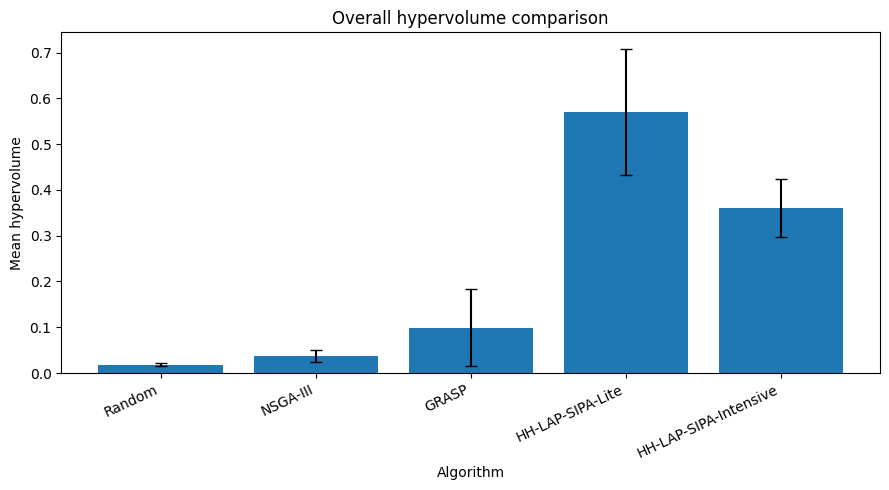

In [18]:
# =========================
# FIGURA 6.1 — MEDIA GLOBAL DE HYPERVOLUME
# =========================

# genera un gráfico de barras con el hypervolume medio global por algoritmo.

plot_df = overall_hv.copy()
plot_df = plot_df.set_index("algorithm").loc[ALGORITHM_ORDER].reset_index()

plt.figure(figsize=(9, 5))

plt.bar(
    plot_df["algorithm_label"],
    plot_df["mean_hv"],
    yerr=plot_df["ci95_half_width"],
    capsize=4
)

plt.ylabel("Mean hypervolume")
plt.xlabel("Algorithm")
plt.title("Overall hypervolume comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "6_1_Overall_hypervolume_comparison/fig_6_1_overall_hypervolume.png", dpi=300)
plt.show()

## Hypervolume by instance size

In [19]:
# =========================
# HYPERVOLUME POR TAMAÑO DE INSTANCIA
# =========================

hv_by_size = (
    hv_summary
    .groupby(["n_students", "algorithm", "algorithm_label"], observed=True)["mean_hv"]
    .agg(
        n_instances="count",
        mean_hv="mean",
        std_hv="std",
        median_hv="median",
        min_hv="min",
        max_hv="max"
    )
    .reset_index()
)

hv_by_size["ci95_half_width"] = (
    hv_summary
    .groupby(["n_students", "algorithm", "algorithm_label"], observed=True)["mean_hv"]
    .apply(ci95)
    .reset_index(drop=True)
)

hv_by_size["ci95_low"] = hv_by_size["mean_hv"] - hv_by_size["ci95_half_width"]
hv_by_size["ci95_high"] = hv_by_size["mean_hv"] + hv_by_size["ci95_half_width"]

display(hv_by_size)

,n_students,algorithm,algorithm_label,n_instances,mean_hv,std_hv,median_hv,min_hv,max_hv,ci95_half_width,ci95_low,ci95_high
0,200,random,Random,4,0.026412,0.005733,0.026098,0.020290,0.033161,0.009122,0.017290,0.035534
1,200,nsga3,NSGA-III,4,0.071240,0.043632,0.058959,0.033329,0.133710,0.069429,0.001811,0.140668
2,200,grasp,GRASP,4,0.443668,0.095357,0.450796,0.346370,0.526713,0.151734,0.291935,0.595402
3,200,hh_lap_v0,HH-LAP-SIPA-Lite,4,0.594188,0.354062,0.742667,0.066624,0.824794,0.563392,0.030797,1.157580
4,200,hh_lap_v1,HH-LAP-SIPA-Intensive,4,0.508306,0.176006,0.433864,0.395363,0.770131,0.280065,0.228240,0.788371
5,400,random,Random,4,0.020909,0.003306,0.021589,0.016632,0.023825,0.005260,0.015649,0.026169
6,400,nsga3,NSGA-III,4,0.047618,0.010553,0.047812,0.036303,0.058543,0.016792,0.030826,0.064410
7,400,grasp,GRASP,4,0.018347,0.004775,0.019016,0.012806,0.022549,0.007598,0.010749,0.025945
8,400,hh_lap_v0,HH-LAP-SIPA-Lite,4,0.385029,0.365721,0.374322,0.068451,0.723022,0.581943,-0.196914,0.966973
9,400,hh_lap_v1,HH-LAP-SIPA-Intensive,4,0.420269,0.116047,0.387044,0.322670,0.584317,0.184656,0.235613,0.604925


In [20]:
hv_by_size.to_csv(OUTPUT_DIR / "6_2_Hypervolume_by_instance_size/hv_by_instance_size.csv", index=False)

In [21]:
# =========================
# TABLA PIVOT 6.2
# =========================

# genera una tabla mucho más legible: filas = tamaño, columnas = algoritmo

hv_by_size_pivot = hv_by_size.pivot_table(
    index="n_students",
    columns="algorithm_label",
    values="mean_hv",
    observed=True
)

# Ordenar columnas
hv_by_size_pivot = hv_by_size_pivot[LABEL_ORDER]

display(hv_by_size_pivot)

algorithm_label,Random,NSGA-III,GRASP,HH-LAP-SIPA-Lite,HH-LAP-SIPA-Intensive
n_students,,,,,
200,0.026412,0.071240,0.443668,0.594188,0.508306
400,0.020909,0.047618,0.018347,0.385029,0.420269
600,0.016575,0.028530,0.013163,0.732925,0.341758
800,0.013666,0.019062,0.010070,0.745269,0.275455
1000,0.014258,0.019784,0.010548,0.397978,0.258631


In [22]:
hv_by_size_pivot.to_csv(OUTPUT_DIR / "6_2_Hypervolume_by_instance_size/table_6_2_hv_by_size.csv")

In [23]:
# =========================
# GANADOR POR TAMAÑO
# =========================

winners_by_size = []

for n_students, row in hv_by_size_pivot.iterrows():
    sorted_row = row.sort_values(ascending=False)

    winners_by_size.append({
        "n_students": n_students,
        "best_algorithm_label": sorted_row.index[0],
        "best_mean_hv": sorted_row.iloc[0],
        "second_algorithm_label": sorted_row.index[1],
        "second_mean_hv": sorted_row.iloc[1],
        "gap_best_second": sorted_row.iloc[0] - sorted_row.iloc[1],
    })

winners_by_size = pd.DataFrame(winners_by_size)

display(winners_by_size)

,n_students,best_algorithm_label,best_mean_hv,second_algorithm_label,second_mean_hv,gap_best_second
0,200,HH-LAP-SIPA-Lite,0.594188,HH-LAP-SIPA-Intensive,0.508306,0.085883
1,400,HH-LAP-SIPA-Intensive,0.420269,HH-LAP-SIPA-Lite,0.385029,0.035240
2,600,HH-LAP-SIPA-Lite,0.732925,HH-LAP-SIPA-Intensive,0.341758,0.391167
3,800,HH-LAP-SIPA-Lite,0.745269,HH-LAP-SIPA-Intensive,0.275455,0.469814
4,1000,HH-LAP-SIPA-Lite,0.397978,HH-LAP-SIPA-Intensive,0.258631,0.139348


In [24]:
winners_by_size.to_csv(OUTPUT_DIR / "6_2_Hypervolume_by_instance_size/winners_by_size.csv", index=False)

In [25]:
# =========================
# RANKING POR TAMAÑO
# =========================

rank_by_size = hv_by_size_pivot.rank(
    axis=1,
    ascending=False,
    method="average"
)

display(rank_by_size)

algorithm_label,Random,NSGA-III,GRASP,HH-LAP-SIPA-Lite,HH-LAP-SIPA-Intensive
n_students,,,,,
200,5.0,4.0,3.0,1.0,2.0
400,4.0,3.0,5.0,2.0,1.0
600,4.0,3.0,5.0,1.0,2.0
800,4.0,3.0,5.0,1.0,2.0
1000,4.0,3.0,5.0,1.0,2.0


In [26]:
rank_by_size.to_csv(OUTPUT_DIR / "6_2_Hypervolume_by_instance_size/rank_by_size.csv")

### Gráficos (hv por tamaño y de ranking)

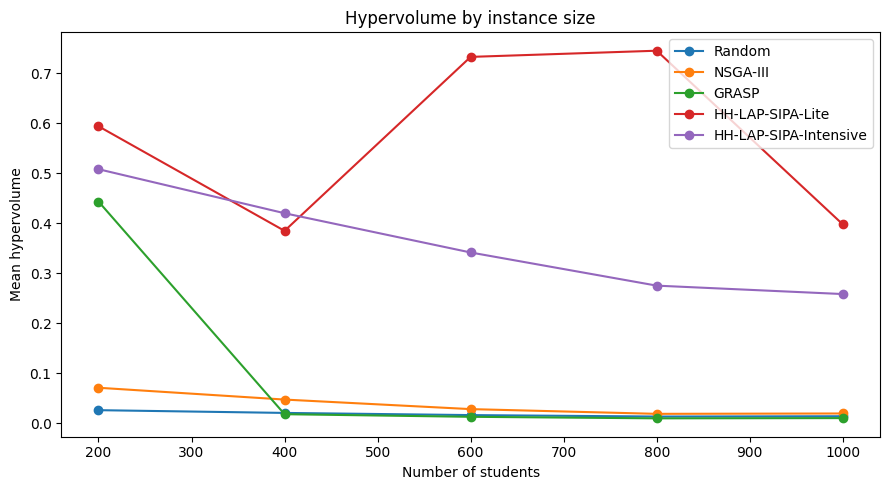

In [31]:
# =========================
# FIGURA 6.2 — HYPERVOLUME POR TAMAÑO
# =========================

plt.figure(figsize=(9, 5))

for alg in ALGORITHM_ORDER:
    sub = (
        hv_by_size[hv_by_size["algorithm"] == alg]
        .sort_values("n_students")
    )

    plt.plot(
        sub["n_students"],
        sub["mean_hv"],
        marker="o",
        label=ALGORITHM_LABELS[alg]
    )
    
plt.xlabel("Number of students")
plt.ylabel("Mean hypervolume")
plt.title("Hypervolume by instance size")
plt.legend()
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "6_2_Hypervolume_by_instance_size/fig_6_2_hypervolume_by_size.png", dpi=300)
plt.show()

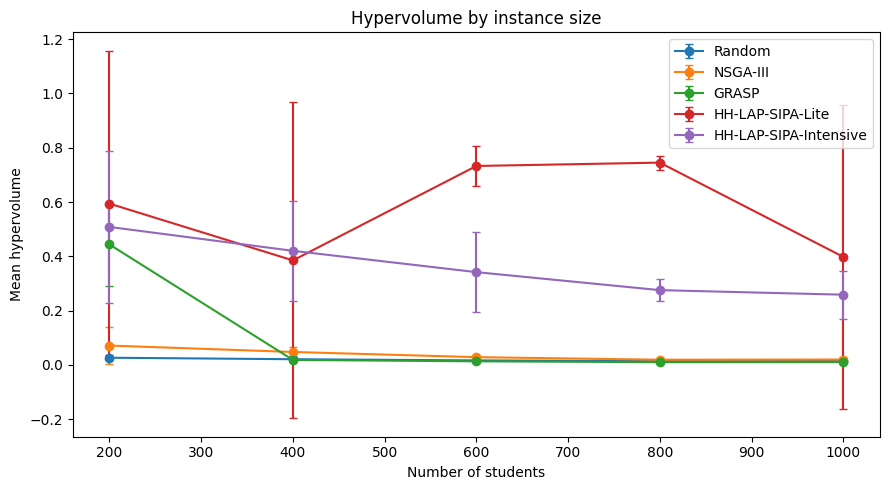

In [28]:
# =========================
# FIGURA 6.2 — HYPERVOLUME POR TAMAÑO CON IC 95%
# =========================

out_dir = OUTPUT_DIR / "6_2_Hypervolume_by_instance_size"
out_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))

for alg in ALGORITHM_ORDER:
    sub = (
        hv_by_size[hv_by_size["algorithm"] == alg]
        .sort_values("n_students")
    )

    plt.errorbar(
        sub["n_students"],
        sub["mean_hv"],
        yerr=sub["ci95_half_width"],
        marker="o",
        capsize=3,
        label=ALGORITHM_LABELS[alg]
    )

plt.xlabel("Number of students")
plt.ylabel("Mean hypervolume")
plt.title("Hypervolume by instance size")
plt.legend()
plt.tight_layout()

plt.savefig(out_dir / "fig_6_2_hypervolume_by_size_with_ci95.png", dpi=300)
plt.show()

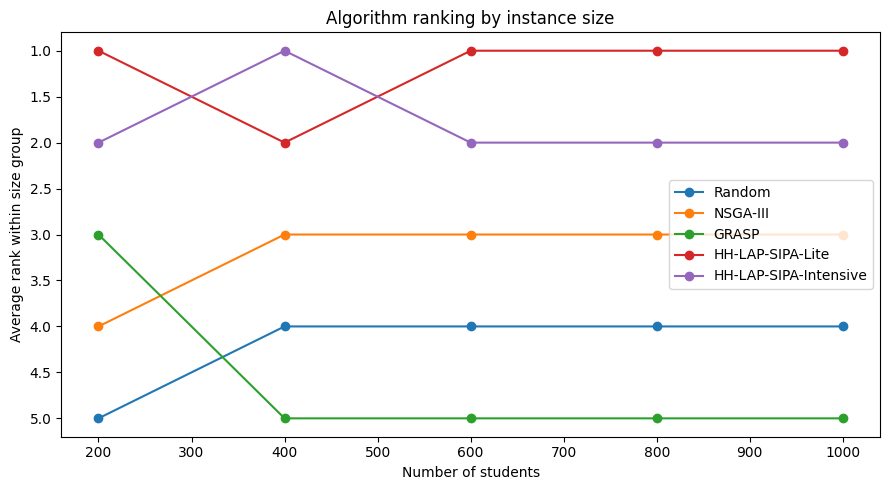

In [54]:
# =========================
# FIGURA 6.2 — RANKING POR TAMAÑO
# =========================

rank_by_size_long = (
    rank_by_size
    .reset_index()
    .melt(
        id_vars="n_students",
        var_name="algorithm_label",
        value_name="rank"
    )
)

plt.figure(figsize=(9, 5))

for alg_label in LABEL_ORDER:
    sub = (
        rank_by_size_long[rank_by_size_long["algorithm_label"] == alg_label]
        .sort_values("n_students")
    )

    plt.plot(
        sub["n_students"],
        sub["rank"],
        marker="o",
        label=alg_label
    )

plt.xlabel("Number of students")
plt.ylabel("Average rank within size group")
plt.title("Algorithm ranking by instance size")
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "6_2_Hypervolume_by_instance_size/fig_6_2_rank_by_size.png", dpi=300)
plt.show()

In [32]:
# ============================================================
# RANKING POR TAMAÑO USANDO TODAS LAS REPETICIONES
# Rank 1 = mejor algoritmo en hypervolume
# ============================================================

rank_run_pivot = hv_run.pivot_table(
    index=["n_students", "instance_clean", "run_id"],
    columns="algorithm",
    values="hypervolume",
    observed=True
)

# Asegurar orden de algoritmos
rank_run_pivot = rank_run_pivot[ALGORITHM_ORDER]

# Ranking dentro de cada instancia y repetición
# Hypervolume: mayor es mejor
rank_by_run = rank_run_pivot.rank(
    axis=1,
    ascending=False,
    method="average"
)

rank_by_run_long = (
    rank_by_run
    .reset_index()
    .melt(
        id_vars=["n_students", "instance_clean", "run_id"],
        var_name="algorithm",
        value_name="rank"
    )
)

rank_by_run_long["algorithm_label"] = (
    rank_by_run_long["algorithm"].map(ALGORITHM_LABELS)
)

rank_by_run_size = (
    rank_by_run_long
    .groupby(["n_students", "algorithm", "algorithm_label"], observed=True)
    .agg(
        n_observations=("rank", "count"),
        mean_rank=("rank", "mean"),
        std_rank=("rank", "std"),
        median_rank=("rank", "median"),
        q25_rank=("rank", lambda x: x.quantile(0.25)),
        q75_rank=("rank", lambda x: x.quantile(0.75)),
        min_rank=("rank", "min"),
        max_rank=("rank", "max"),
        ci95_half_width=("rank", ci95),
    )
    .reset_index()
)

rank_by_run_size["ci95_low"] = (
    rank_by_run_size["mean_rank"] - rank_by_run_size["ci95_half_width"]
)

rank_by_run_size["ci95_high"] = (
    rank_by_run_size["mean_rank"] + rank_by_run_size["ci95_half_width"]
)

display(rank_by_run_size)

out_dir = OUTPUT_DIR / "6_2_Hypervolume_by_instance_size"
out_dir.mkdir(parents=True, exist_ok=True)

rank_by_run_long.to_csv(
    out_dir / "rank_by_run_long.csv",
    index=False
)

rank_by_run_size.to_csv(
    out_dir / "rank_by_run_size_summary.csv",
    index=False
)

,n_students,algorithm,algorithm_label,n_observations,mean_rank,std_rank,median_rank,q25_rank,q75_rank,min_rank,max_rank,ci95_half_width,ci95_low,ci95_high
0,200,grasp,GRASP,120,2.433333,0.545930,2.0,2.00,3.00,2.0,5.0,0.098681,2.334652,2.532014
1,200,hh_lap_v0,HH-LAP-SIPA-Lite,120,1.750000,1.304485,1.0,1.00,1.75,1.0,4.0,0.235795,1.514205,1.985795
2,200,hh_lap_v1,HH-LAP-SIPA-Intensive,120,2.083333,0.762386,2.0,1.75,3.00,1.0,3.0,0.137807,1.945526,2.221140
3,200,nsga3,NSGA-III,120,3.750000,0.453743,4.0,3.00,4.00,3.0,5.0,0.082017,3.667983,3.832017
4,200,random,Random,120,4.983333,0.128556,5.0,5.00,5.00,4.0,5.0,0.023237,4.960096,5.006571
5,400,grasp,GRASP,120,4.858333,0.350170,5.0,5.00,5.00,4.0,5.0,0.063296,4.795037,4.921629
6,400,hh_lap_v0,HH-LAP-SIPA-Lite,120,1.500000,0.502096,1.5,1.00,2.00,1.0,2.0,0.090758,1.409242,1.590758
7,400,hh_lap_v1,HH-LAP-SIPA-Intensive,120,1.500000,0.502096,1.5,1.00,2.00,1.0,2.0,0.090758,1.409242,1.590758
8,400,nsga3,NSGA-III,120,3.000000,0.000000,3.0,3.00,3.00,3.0,3.0,0.000000,3.000000,3.000000
9,400,random,Random,120,4.141667,0.350170,4.0,4.00,4.00,4.0,5.0,0.063296,4.078371,4.204963


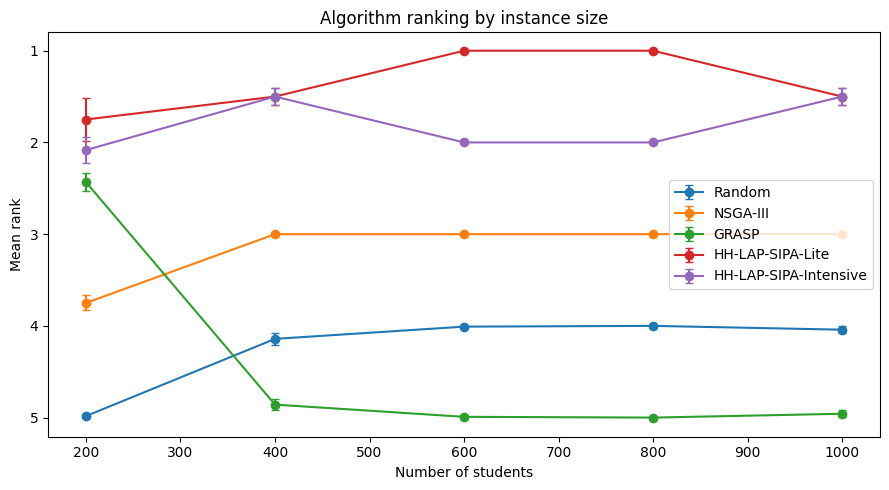

In [33]:
# ============================================================
# FIGURA — RANKING MEDIO POR TAMAÑO CON IC 95%
# ============================================================

plt.figure(figsize=(9, 5))

for alg in ALGORITHM_ORDER:
    sub = (
        rank_by_run_size[rank_by_run_size["algorithm"] == alg]
        .sort_values("n_students")
    )

    yerr = np.vstack([
        sub["mean_rank"] - sub["ci95_low"],
        sub["ci95_high"] - sub["mean_rank"]
    ])

    plt.errorbar(
        sub["n_students"],
        sub["mean_rank"],
        yerr=yerr,
        marker="o",
        capsize=3,
        label=ALGORITHM_LABELS[alg]
    )

plt.xlabel("Number of students")
plt.ylabel("Mean rank")
plt.title("Algorithm ranking by instance size")
plt.yticks([1, 2, 3, 4, 5])
plt.gca().invert_yaxis()  # rank 1 arriba
plt.legend()
plt.tight_layout()

plt.savefig(
    out_dir / "fig_6_2_rank_by_size_with_ci95.png",
    dpi=300
)

plt.show()

## Instance-level variability

In [57]:
# ============================================================
# 6.3 INSTANCE-LEVEL VARIABILITY
# Tabla de hypervolume medio por instancia y algoritmo
# ============================================================

def extract_instance_index(instance_name):
    """
    Extrae el índice final de la instancia.
    Ejemplo: problem_instance_ext_600_2 -> 2
    """
    match = re.search(r"_(\d+)$", str(instance_name))
    if match:
        return int(match.group(1))
    return -1


hv_instance_pivot = hv_summary.pivot_table(
    index=["n_students", "instance_clean"],
    columns="algorithm_label",
    values="mean_hv",
    observed=True
)

# Ordenar columnas de algoritmos
hv_instance_pivot = hv_instance_pivot[LABEL_ORDER]

# Pasar a tabla normal
hv_instance_table = hv_instance_pivot.reset_index()

# Añadir índice de instancia para ordenar mejor
hv_instance_table["instance_id"] = hv_instance_table["instance_clean"].apply(extract_instance_index)

hv_instance_table = (
    hv_instance_table
    .sort_values(["n_students", "instance_id"])
    .drop(columns=["instance_id"])
)

display(hv_instance_table)

algorithm_label,n_students,instance_clean,Random,NSGA-III,GRASP,HH-LAP-SIPA-Lite,HH-LAP-SIPA-Intensive
0,200,problem_instance_ext_200_0,0.023326,0.064872,0.346370,0.727109,0.417390
1,200,problem_instance_ext_200_1,0.020290,0.053046,0.377264,0.758226,0.395363
2,200,problem_instance_ext_200_2,0.028870,0.033329,0.526713,0.824794,0.450339
3,200,problem_instance_ext_200_3,0.033161,0.133710,0.524327,0.066624,0.770131
4,400,problem_instance_ext_400_0,0.016632,0.036303,0.012806,0.723022,0.322670
5,400,problem_instance_ext_400_1,0.019999,0.041231,0.015923,0.679744,0.357420
6,400,problem_instance_ext_400_2,0.023825,0.054394,0.022549,0.068900,0.416669
7,400,problem_instance_ext_400_3,0.023179,0.058543,0.022110,0.068451,0.584317
8,600,problem_instance_ext_600_0,0.017527,0.029318,0.015853,0.719440,0.477161
9,600,problem_instance_ext_600_1,0.015297,0.026107,0.012111,0.771071,0.295327


In [58]:
hv_instance_table.to_csv(
    OUTPUT_DIR / "6_3_Instance_level_variability/table_6_3_hv_by_instance_algorithm.csv",
    index=False
)

In [59]:
# ============================================================
# GANADOR Y SEGUNDO MEJOR POR INSTANCIA
# ============================================================

instance_winner_rows = []

for _, row in hv_instance_table.iterrows():
    n_students = row["n_students"]
    instance_clean = row["instance_clean"]

    hv_values = row[LABEL_ORDER].astype(float).sort_values(ascending=False)

    best_algorithm = hv_values.index[0]
    second_algorithm = hv_values.index[1]

    instance_winner_rows.append({
        "n_students": n_students,
        "instance_clean": instance_clean,
        "best_algorithm": best_algorithm,
        "best_mean_hv": hv_values.iloc[0],
        "second_algorithm": second_algorithm,
        "second_mean_hv": hv_values.iloc[1],
        "gap_best_second": hv_values.iloc[0] - hv_values.iloc[1],
    })

instance_winners_6_3 = pd.DataFrame(instance_winner_rows)

display(instance_winners_6_3)

,n_students,instance_clean,best_algorithm,best_mean_hv,second_algorithm,second_mean_hv,gap_best_second
0,200,problem_instance_ext_200_0,HH-LAP-SIPA-Lite,0.727109,HH-LAP-SIPA-Intensive,0.417390,0.309719
1,200,problem_instance_ext_200_1,HH-LAP-SIPA-Lite,0.758226,HH-LAP-SIPA-Intensive,0.395363,0.362863
2,200,problem_instance_ext_200_2,HH-LAP-SIPA-Lite,0.824794,GRASP,0.526713,0.298081
3,200,problem_instance_ext_200_3,HH-LAP-SIPA-Intensive,0.770131,GRASP,0.524327,0.245804
4,400,problem_instance_ext_400_0,HH-LAP-SIPA-Lite,0.723022,HH-LAP-SIPA-Intensive,0.322670,0.400352
5,400,problem_instance_ext_400_1,HH-LAP-SIPA-Lite,0.679744,HH-LAP-SIPA-Intensive,0.357420,0.322325
6,400,problem_instance_ext_400_2,HH-LAP-SIPA-Intensive,0.416669,HH-LAP-SIPA-Lite,0.068900,0.347769
7,400,problem_instance_ext_400_3,HH-LAP-SIPA-Intensive,0.584317,HH-LAP-SIPA-Lite,0.068451,0.515866
8,600,problem_instance_ext_600_0,HH-LAP-SIPA-Lite,0.719440,HH-LAP-SIPA-Intensive,0.477161,0.242278
9,600,problem_instance_ext_600_1,HH-LAP-SIPA-Lite,0.771071,HH-LAP-SIPA-Intensive,0.295327,0.475744


In [60]:
instance_winners_6_3.to_csv(
    OUTPUT_DIR / "6_3_Instance_level_variability/table_6_3_instance_winners.csv",
    index=False
)

In [61]:
# ============================================================
# CONTEO DE VICTORIAS POR ALGORITMO
# ============================================================

instance_win_counts_6_3 = (
    instance_winners_6_3
    .groupby("best_algorithm")
    .size()
    .reset_index(name="n_instance_wins")
    .sort_values("n_instance_wins", ascending=False)
)

display(instance_win_counts_6_3)

,best_algorithm,n_instance_wins
1,HH-LAP-SIPA-Lite,15
0,HH-LAP-SIPA-Intensive,5


In [62]:
# ============================================================
# CONTEO DE VICTORIAS POR TAMAÑO
# ============================================================

instance_win_counts_by_size_6_3 = (
    instance_winners_6_3
    .groupby(["n_students", "best_algorithm"])
    .size()
    .reset_index(name="n_instance_wins")
    .sort_values(["n_students", "n_instance_wins"], ascending=[True, False])
)

display(instance_win_counts_by_size_6_3)

,n_students,best_algorithm,n_instance_wins
1,200,HH-LAP-SIPA-Lite,3
0,200,HH-LAP-SIPA-Intensive,1
2,400,HH-LAP-SIPA-Intensive,2
3,400,HH-LAP-SIPA-Lite,2
4,600,HH-LAP-SIPA-Lite,4
5,800,HH-LAP-SIPA-Lite,4
6,1000,HH-LAP-SIPA-Intensive,2
7,1000,HH-LAP-SIPA-Lite,2


In [63]:
instance_win_counts_6_3.to_csv(
    OUTPUT_DIR / "6_3_Instance_level_variability/table_6_3_instance_win_counts.csv",
    index=False
)

instance_win_counts_by_size_6_3.to_csv(
    OUTPUT_DIR / "6_3_Instance_level_variability/table_6_3_instance_win_counts_by_size.csv",
    index=False
)

In [64]:
# ============================================================
# COMPARACIÓN DIRECTA HH-LAP-SIPA-LITE VS INTENSIVE
# ============================================================

lite_label = "HH-LAP-SIPA-Lite"
intensive_label = "HH-LAP-SIPA-Intensive"

lite_vs_intensive = hv_instance_table[[
    "n_students",
    "instance_clean",
    lite_label,
    intensive_label
]].copy()

lite_vs_intensive["diff_lite_minus_intensive"] = (
    lite_vs_intensive[lite_label] - lite_vs_intensive[intensive_label]
)

lite_vs_intensive["best_variant"] = np.where(
    lite_vs_intensive["diff_lite_minus_intensive"] >= 0,
    lite_label,
    intensive_label
)

lite_vs_intensive["abs_diff"] = lite_vs_intensive["diff_lite_minus_intensive"].abs()

display(lite_vs_intensive)

algorithm_label,n_students,instance_clean,HH-LAP-SIPA-Lite,HH-LAP-SIPA-Intensive,diff_lite_minus_intensive,best_variant,abs_diff
0,200,problem_instance_ext_200_0,0.727109,0.417390,0.309719,HH-LAP-SIPA-Lite,0.309719
1,200,problem_instance_ext_200_1,0.758226,0.395363,0.362863,HH-LAP-SIPA-Lite,0.362863
2,200,problem_instance_ext_200_2,0.824794,0.450339,0.374455,HH-LAP-SIPA-Lite,0.374455
3,200,problem_instance_ext_200_3,0.066624,0.770131,-0.703508,HH-LAP-SIPA-Intensive,0.703508
4,400,problem_instance_ext_400_0,0.723022,0.322670,0.400352,HH-LAP-SIPA-Lite,0.400352
5,400,problem_instance_ext_400_1,0.679744,0.357420,0.322325,HH-LAP-SIPA-Lite,0.322325
6,400,problem_instance_ext_400_2,0.068900,0.416669,-0.347769,HH-LAP-SIPA-Intensive,0.347769
7,400,problem_instance_ext_400_3,0.068451,0.584317,-0.515866,HH-LAP-SIPA-Intensive,0.515866
8,600,problem_instance_ext_600_0,0.719440,0.477161,0.242278,HH-LAP-SIPA-Lite,0.242278
9,600,problem_instance_ext_600_1,0.771071,0.295327,0.475744,HH-LAP-SIPA-Lite,0.475744


In [65]:
lite_vs_intensive_summary = (
    lite_vs_intensive
    .groupby("best_variant")
    .size()
    .reset_index(name="n_instances")
    .sort_values("n_instances", ascending=False)
)

display(lite_vs_intensive_summary)

,best_variant,n_instances
1,HH-LAP-SIPA-Lite,15
0,HH-LAP-SIPA-Intensive,5


In [66]:
lite_vs_intensive.to_csv(
    OUTPUT_DIR / "6_3_Instance_level_variability/table_6_3_lite_vs_intensive_by_instance.csv",
    index=False
)

lite_vs_intensive_summary.to_csv(
    OUTPUT_DIR / "6_3_Instance_level_variability/table_6_3_lite_vs_intensive_summary.csv",
    index=False
)

### Figuras

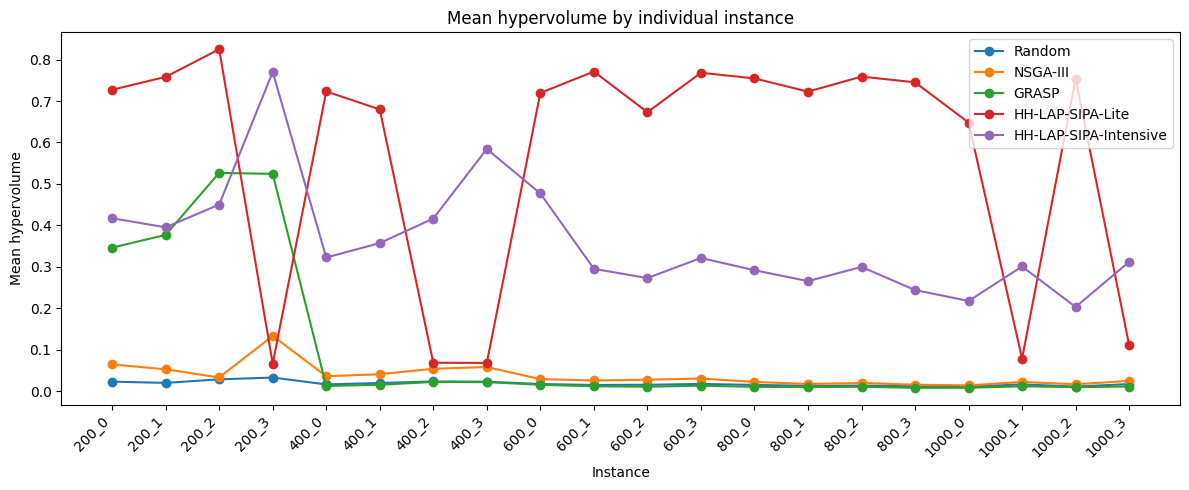

In [67]:
# ============================================================
# FIGURA 6.3 — HYPERVOLUME POR INSTANCIA
# ============================================================

plot_instance_table = hv_instance_table.copy()
plot_instance_table["instance_short"] = (
    plot_instance_table["n_students"].astype(str)
    + "_"
    + plot_instance_table["instance_clean"].apply(extract_instance_index).astype(str)
)

plt.figure(figsize=(12, 5))

for alg_label in LABEL_ORDER:
    plt.plot(
        plot_instance_table["instance_short"],
        plot_instance_table[alg_label],
        marker="o",
        label=alg_label
    )

plt.xlabel("Instance")
plt.ylabel("Mean hypervolume")
plt.title("Mean hypervolume by individual instance")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "6_3_Instance_level_variability/fig_6_3_hypervolume_by_instance.png", dpi=300)
plt.show()

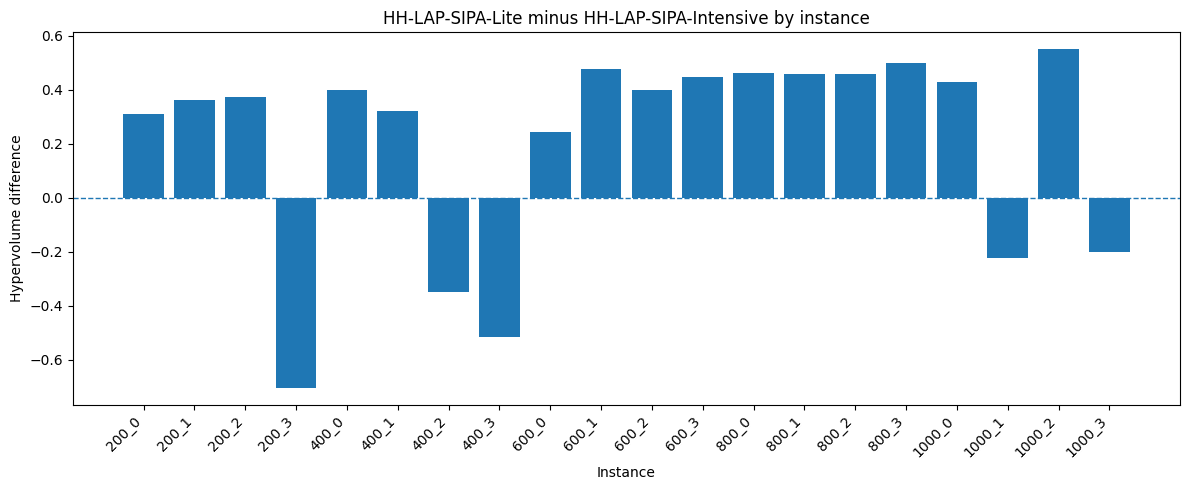

In [68]:
# ============================================================
# FIGURA 6.3 — DIFERENCIA LITE - INTENSIVE
# ============================================================

plot_diff = lite_vs_intensive.copy()
plot_diff["instance_short"] = (
    plot_diff["n_students"].astype(str)
    + "_"
    + plot_diff["instance_clean"].apply(extract_instance_index).astype(str)
)

plt.figure(figsize=(12, 5))

plt.bar(
    plot_diff["instance_short"],
    plot_diff["diff_lite_minus_intensive"]
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Instance")
plt.ylabel("Hypervolume difference")
plt.title("HH-LAP-SIPA-Lite minus HH-LAP-SIPA-Intensive by instance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "6_3_Instance_level_variability/fig_6_3_lite_minus_intensive_by_instance.png", dpi=300)
plt.show()

## Per-objective performance analysis

In [69]:
# ============================================================
# 6.4 PER-OBJECTIVE PERFORMANCE ANALYSIS
# Cargar todos los frentes Pareto
# ============================================================

PARETO_DIR = ROOT / "pareto"

if not PARETO_DIR.exists():
    raise FileNotFoundError(f"No se ha encontrado la carpeta de Pareto: {PARETO_DIR}")

pareto_files = sorted(PARETO_DIR.glob("*.csv"))

print("Número de archivos Pareto encontrados:", len(pareto_files))

expected_pareto_files = 20 * 5 * 30

if len(pareto_files) != expected_pareto_files:
    print(f"WARNING: expected {expected_pareto_files} Pareto files, found {len(pareto_files)}")
else:
    print("Pareto files check OK.")

Número de archivos Pareto encontrados: 3000
Pareto files check OK.


In [70]:
# ============================================================
# LECTURA DE PARETO FRONTS
# ============================================================

pareto_dfs = []

required_objective_cols = [
    "tau_sum",
    "eta_sum",
    "lbar_sum",
    "sigma_sum"
]

for file in pareto_files:
    df = pd.read_csv(file)

    missing_cols = [c for c in required_objective_cols if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Faltan columnas {missing_cols} en {file.name}")

    df["source_file"] = file.name
    df["instance_clean"] = df["instance"].apply(normalize_instance_name)
    df["algorithm_label"] = df["algorithm"].map(ALGORITHM_LABELS)

    pareto_dfs.append(df)

pareto_all = pd.concat(pareto_dfs, ignore_index=True)

pareto_all["algorithm"] = pd.Categorical(
    pareto_all["algorithm"],
    categories=ALGORITHM_ORDER,
    ordered=True
)

display(pareto_all.head())
print("Filas totales en Pareto:", len(pareto_all))

,timestamp,algorithm,instance,n_students,run_id,solution_id,seed,iteration,objective_value,tau_sum,eta_sum,lbar_sum,sigma_sum,source_file,instance_clean,algorithm_label
0,2026-05-25 11:08:29,grasp,problem_instance_ext_1000_0.txt,1000,0,0,848885973,1,80.833338,173.643586,58.4078,1.912968,0.020538,grasp__problem_instance_ext_1000_0__run_00.csv,problem_instance_ext_1000_0,GRASP
1,2026-05-25 11:08:29,grasp,problem_instance_ext_1000_0.txt,1000,0,1,848885973,2,75.657912,165.489171,51.7684,1.905797,0.010778,grasp__problem_instance_ext_1000_0__run_00.csv,problem_instance_ext_1000_0,GRASP
2,2026-05-25 11:18:30,grasp,problem_instance_ext_1000_0.txt,1000,1,0,848885974,1,75.657912,165.489171,51.7684,1.905797,0.010778,grasp__problem_instance_ext_1000_0__run_01.csv,problem_instance_ext_1000_0,GRASP
3,2026-05-25 11:28:31,grasp,problem_instance_ext_1000_0.txt,1000,2,0,848885975,1,73.723009,164.593898,47.1396,1.910836,0.015476,grasp__problem_instance_ext_1000_0__run_02.csv,problem_instance_ext_1000_0,GRASP
4,2026-05-25 11:28:31,grasp,problem_instance_ext_1000_0.txt,1000,2,1,848885975,2,74.631710,163.361836,50.9865,1.915664,0.070748,grasp__problem_instance_ext_1000_0__run_02.csv,problem_instance_ext_1000_0,GRASP


Filas totales en Pareto: 163905


In [71]:
pareto_all.to_csv(
    OUTPUT_DIR / "6_4_Per_objective_performance_analysis/all_pareto_solutions.csv",
    index=False
)

In [72]:
# ============================================================
# OBJETIVOS NORMALIZADOS POR ESTUDIANTE
# ============================================================

pareto_all["tau_per_student"] = pareto_all["tau_sum"] / pareto_all["n_students"]
pareto_all["eta_per_student"] = pareto_all["eta_sum"] / pareto_all["n_students"]

display(pareto_all[[
    "algorithm_label",
    "instance_clean",
    "run_id",
    "tau_sum",
    "eta_sum",
    "tau_per_student",
    "eta_per_student",
    "lbar_sum",
    "sigma_sum"
]].head())

,algorithm_label,instance_clean,run_id,tau_sum,eta_sum,tau_per_student,eta_per_student,lbar_sum,sigma_sum
0,GRASP,problem_instance_ext_1000_0,0,173.643586,58.4078,0.173644,0.058408,1.912968,0.020538
1,GRASP,problem_instance_ext_1000_0,0,165.489171,51.7684,0.165489,0.051768,1.905797,0.010778
2,GRASP,problem_instance_ext_1000_0,1,165.489171,51.7684,0.165489,0.051768,1.905797,0.010778
3,GRASP,problem_instance_ext_1000_0,2,164.593898,47.1396,0.164594,0.047140,1.910836,0.015476
4,GRASP,problem_instance_ext_1000_0,2,163.361836,50.9865,0.163362,0.050987,1.915664,0.070748


In [73]:
# ============================================================
# MEJOR VALOR POR OBJETIVO EN CADA RUN
# ============================================================

run_objective_summary = (
    pareto_all
    .groupby(
        ["algorithm", "algorithm_label", "instance_clean", "n_students", "run_id"],
        observed=True
    )
    .agg(
        pareto_size=("solution_id", "count"),

        best_tau_sum=("tau_sum", "max"),
        best_eta_sum=("eta_sum", "max"),
        best_lbar_sum=("lbar_sum", "min"),
        best_sigma_sum=("sigma_sum", "min"),

        best_tau_per_student=("tau_per_student", "max"),
        best_eta_per_student=("eta_per_student", "max"),

        mean_tau_sum=("tau_sum", "mean"),
        mean_eta_sum=("eta_sum", "mean"),
        mean_lbar_sum=("lbar_sum", "mean"),
        mean_sigma_sum=("sigma_sum", "mean"),
    )
    .reset_index()
)

display(run_objective_summary.head())

,algorithm,algorithm_label,instance_clean,n_students,run_id,pareto_size,best_tau_sum,best_eta_sum,best_lbar_sum,best_sigma_sum,best_tau_per_student,best_eta_per_student,mean_tau_sum,mean_eta_sum,mean_lbar_sum,mean_sigma_sum
0,random,Random,problem_instance_ext_1000_0,1000,0,76,179.400202,64.602,1.895476,0.007586,0.1794,0.064602,169.140624,51.998196,1.920867,0.062611
1,random,Random,problem_instance_ext_1000_0,1000,1,76,179.400202,64.602,1.895476,0.007586,0.1794,0.064602,169.140624,51.998196,1.920867,0.062611
2,random,Random,problem_instance_ext_1000_0,1000,2,76,179.400202,64.602,1.895476,0.007586,0.1794,0.064602,169.140624,51.998196,1.920867,0.062611
3,random,Random,problem_instance_ext_1000_0,1000,3,73,179.400202,64.602,1.895476,0.007586,0.1794,0.064602,169.154057,51.957240,1.920993,0.063034
4,random,Random,problem_instance_ext_1000_0,1000,4,73,179.400202,64.602,1.895476,0.007586,0.1794,0.064602,169.154057,51.957240,1.920993,0.063034


In [74]:
run_objective_summary.to_csv(
    OUTPUT_DIR / "6_4_Per_objective_performance_analysis/table_6_4_run_objective_summary.csv",
    index=False
)

In [75]:
# ============================================================
# RESUMEN POR ALGORITMO-INSTANCIA
# ============================================================

instance_objective_summary = (
    run_objective_summary
    .groupby(
        ["algorithm", "algorithm_label", "instance_clean", "n_students"],
        observed=True
    )
    .agg(
        mean_best_tau_sum=("best_tau_sum", "mean"),
        std_best_tau_sum=("best_tau_sum", "std"),

        mean_best_eta_sum=("best_eta_sum", "mean"),
        std_best_eta_sum=("best_eta_sum", "std"),

        mean_best_lbar_sum=("best_lbar_sum", "mean"),
        std_best_lbar_sum=("best_lbar_sum", "std"),

        mean_best_sigma_sum=("best_sigma_sum", "mean"),
        std_best_sigma_sum=("best_sigma_sum", "std"),

        mean_best_tau_per_student=("best_tau_per_student", "mean"),
        mean_best_eta_per_student=("best_eta_per_student", "mean"),

        mean_pareto_size=("pareto_size", "mean"),
    )
    .reset_index()
)

display(instance_objective_summary.head())

,algorithm,algorithm_label,instance_clean,n_students,mean_best_tau_sum,std_best_tau_sum,mean_best_eta_sum,std_best_eta_sum,mean_best_lbar_sum,std_best_lbar_sum,mean_best_sigma_sum,std_best_sigma_sum,mean_best_tau_per_student,mean_best_eta_per_student,mean_pareto_size
0,random,Random,problem_instance_ext_1000_0,1000,178.259424,0.840928,65.352800,0.539972,1.895311,0.000119,0.007163,0.000304,0.178259,0.065353,52.466667
1,random,Random,problem_instance_ext_1000_1,1000,184.953265,1.183007,73.324167,0.450024,0.735920,0.000459,0.003094,0.000207,0.184953,0.073324,46.200000
2,random,Random,problem_instance_ext_1000_2,1000,193.080510,0.361598,84.464800,0.148154,1.556100,0.000171,0.001148,0.000181,0.193081,0.084465,52.733333
3,random,Random,problem_instance_ext_1000_3,1000,198.328592,0.245610,88.162267,0.636152,1.176349,0.002402,0.007123,0.001559,0.198329,0.088162,38.666667
4,random,Random,problem_instance_ext_200_0,200,43.727019,0.040232,20.359767,0.189340,2.410135,0.020382,0.081673,0.013760,0.218635,0.101799,103.833333


In [76]:
instance_objective_summary.to_csv(
    OUTPUT_DIR / "6_4_Per_objective_performance_analysis/table_6_4_instance_objective_summary.csv",
    index=False
)

In [77]:
# ============================================================
# RESUMEN GLOBAL POR ALGORITMO Y OBJETIVO
# ============================================================

objective_global_summary = (
    instance_objective_summary
    .groupby(["algorithm", "algorithm_label"], observed=True)
    .agg(
        n_instances=("instance_clean", "count"),

        mean_tau_per_student=("mean_best_tau_per_student", "mean"),
        std_tau_per_student=("mean_best_tau_per_student", "std"),

        mean_eta_per_student=("mean_best_eta_per_student", "mean"),
        std_eta_per_student=("mean_best_eta_per_student", "std"),

        mean_lbar_sum=("mean_best_lbar_sum", "mean"),
        std_lbar_sum=("mean_best_lbar_sum", "std"),

        mean_sigma_sum=("mean_best_sigma_sum", "mean"),
        std_sigma_sum=("mean_best_sigma_sum", "std"),

        mean_pareto_size=("mean_pareto_size", "mean"),
    )
    .reset_index()
)

objective_global_summary = objective_global_summary.sort_values("algorithm")

display(objective_global_summary)

,algorithm,algorithm_label,n_instances,mean_tau_per_student,std_tau_per_student,mean_eta_per_student,std_eta_per_student,mean_lbar_sum,std_lbar_sum,mean_sigma_sum,std_sigma_sum,mean_pareto_size
0,random,Random,20,0.198289,0.011757,0.087610,0.012174,1.687307,1.053381,0.034546,0.052393,66.765000
1,nsga3,NSGA-III,20,0.232055,0.036912,0.124782,0.038116,1.686424,1.054554,0.043240,0.066466,51.096667
2,grasp,GRASP,20,0.272028,0.180646,0.151269,0.161242,1.716826,1.072608,0.050329,0.068394,3.116667
3,hh_lap_v0,HH-LAP-SIPA-Lite,20,0.780861,0.013089,0.580840,0.017662,1.430694,0.818468,0.100277,0.119806,42.083333
4,hh_lap_v1,HH-LAP-SIPA-Intensive,20,0.780769,0.013341,0.580643,0.017209,2.119119,1.367436,0.007381,0.011406,110.113333


In [78]:
objective_global_summary.to_csv(
    OUTPUT_DIR / "6_4_Per_objective_performance_analysis/table_6_4_objective_global_summary.csv",
    index=False
)

In [79]:
# ============================================================
# RANKING MEDIO POR OBJETIVO
# ============================================================

objective_rank_rows = []

objectives_for_ranking = {
    "tau_per_student": {
        "column": "mean_best_tau_per_student",
        "sense": "max"
    },
    "eta_per_student": {
        "column": "mean_best_eta_per_student",
        "sense": "max"
    },
    "lbar_sum": {
        "column": "mean_best_lbar_sum",
        "sense": "min"
    },
    "sigma_sum": {
        "column": "mean_best_sigma_sum",
        "sense": "min"
    },
}

for obj_name, info in objectives_for_ranking.items():
    col = info["column"]
    sense = info["sense"]

    pivot_obj = instance_objective_summary.pivot_table(
        index=["n_students", "instance_clean"],
        columns="algorithm_label",
        values=col,
        observed=True
    )[LABEL_ORDER]

    ranks = pivot_obj.rank(
        axis=1,
        ascending=(sense == "min"),
        method="average"
    )

    avg_rank = ranks.mean(axis=0)

    for alg_label, rank_value in avg_rank.items():
        objective_rank_rows.append({
            "objective": obj_name,
            "algorithm_label": alg_label,
            "average_rank": rank_value,
            "sense": sense
        })

objective_ranks = (
    pd.DataFrame(objective_rank_rows)
    .sort_values(["objective", "average_rank"])
)

display(objective_ranks)

,objective,algorithm_label,average_rank,sense
8,eta_per_student,HH-LAP-SIPA-Lite,1.500,max
9,eta_per_student,HH-LAP-SIPA-Intensive,1.500,max
6,eta_per_student,NSGA-III,3.200,max
5,eta_per_student,Random,4.200,max
7,eta_per_student,GRASP,4.600,max
13,lbar_sum,HH-LAP-SIPA-Lite,1.750,min
11,lbar_sum,NSGA-III,2.100,min
10,lbar_sum,Random,2.400,min
12,lbar_sum,GRASP,3.950,min
14,lbar_sum,HH-LAP-SIPA-Intensive,4.800,min


In [80]:
objective_ranks.to_csv(
    OUTPUT_DIR / "6_4_Per_objective_performance_analysis/table_6_4_average_rank_by_objective.csv",
    index=False
)

In [81]:
# ============================================================
# TABLA COMPACTA 6.4
# ============================================================

table_6_4_objectives = objective_global_summary[[
    "algorithm_label",
    "mean_tau_per_student",
    "std_tau_per_student",
    "mean_eta_per_student",
    "std_eta_per_student",
    "mean_lbar_sum",
    "std_lbar_sum",
    "mean_sigma_sum",
    "std_sigma_sum",
    "mean_pareto_size",
]].copy()

table_6_4_objectives = table_6_4_objectives.rename(columns={
    "algorithm_label": "Algorithm",
    "mean_tau_per_student": "Tau/student mean",
    "std_tau_per_student": "Tau/student std",
    "mean_eta_per_student": "Eta/student mean",
    "std_eta_per_student": "Eta/student std",
    "mean_lbar_sum": "Lbar mean",
    "std_lbar_sum": "Lbar std",
    "mean_sigma_sum": "Sigma mean",
    "std_sigma_sum": "Sigma std",
    "mean_pareto_size": "Pareto size mean",
})

display(table_6_4_objectives)

,Algorithm,Tau/student mean,Tau/student std,Eta/student mean,Eta/student std,Lbar mean,Lbar std,Sigma mean,Sigma std,Pareto size mean
0,Random,0.198289,0.011757,0.087610,0.012174,1.687307,1.053381,0.034546,0.052393,66.765000
1,NSGA-III,0.232055,0.036912,0.124782,0.038116,1.686424,1.054554,0.043240,0.066466,51.096667
2,GRASP,0.272028,0.180646,0.151269,0.161242,1.716826,1.072608,0.050329,0.068394,3.116667
3,HH-LAP-SIPA-Lite,0.780861,0.013089,0.580840,0.017662,1.430694,0.818468,0.100277,0.119806,42.083333
4,HH-LAP-SIPA-Intensive,0.780769,0.013341,0.580643,0.017209,2.119119,1.367436,0.007381,0.011406,110.113333


In [82]:
table_6_4_objectives.to_csv(
    OUTPUT_DIR / "6_4_Per_objective_performance_analysis/table_6_4_per_objective_summary.csv",
    index=False
)

### Figuras

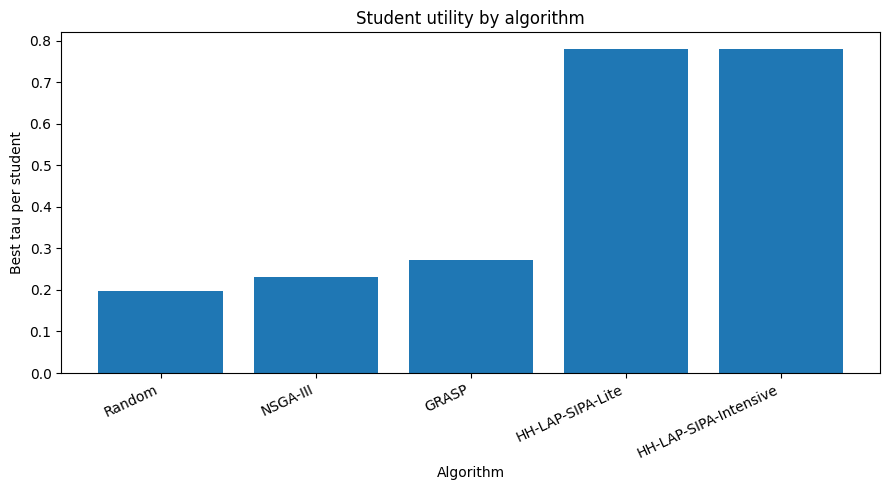

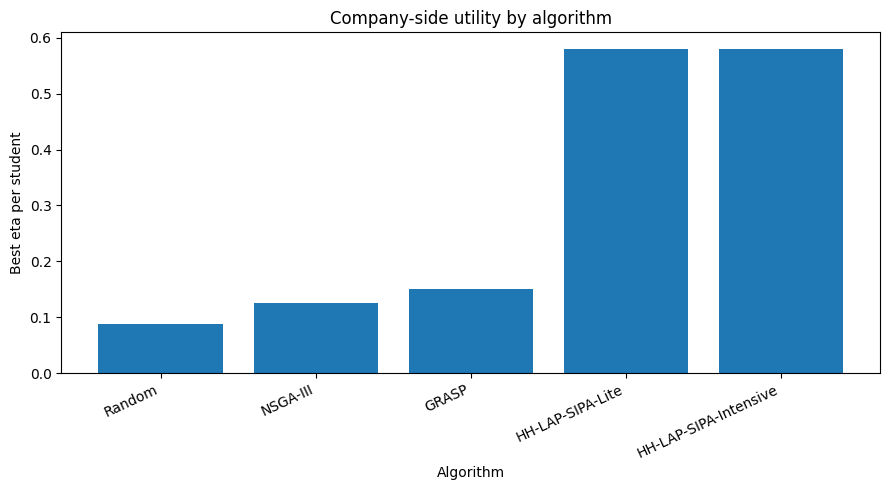

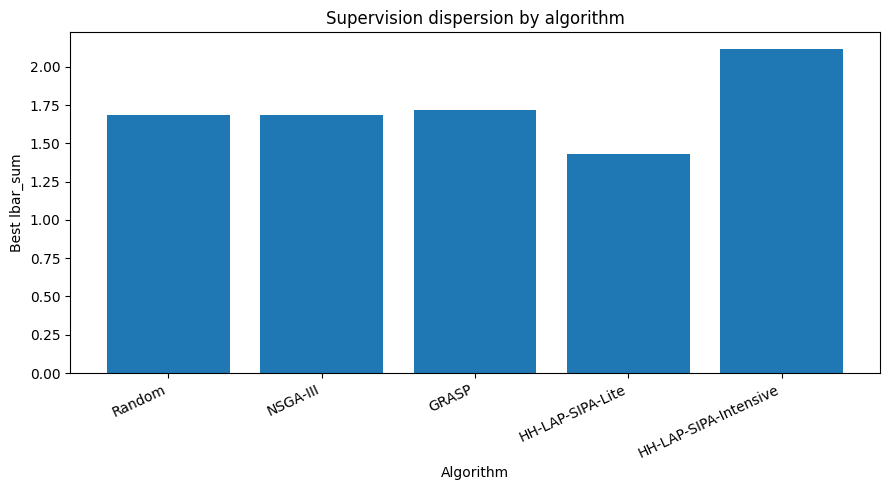

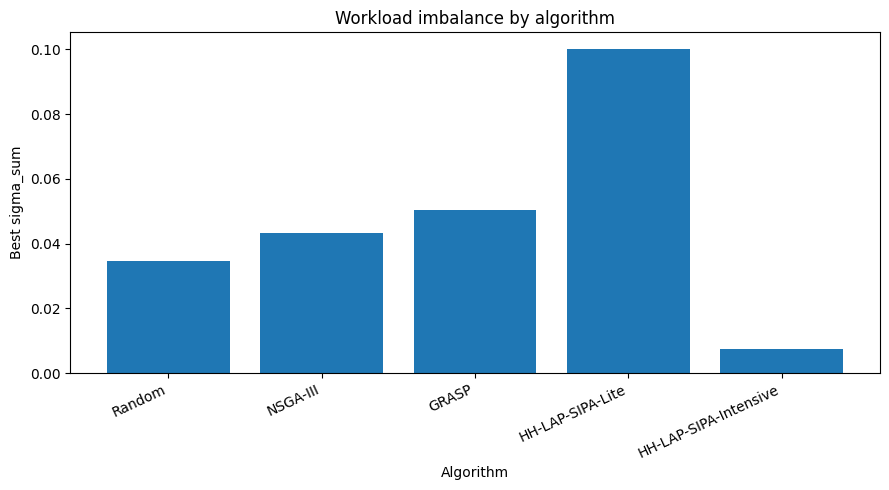

In [83]:
# ============================================================
# FIGURAS 6.4 — COMPARACIÓN POR OBJETIVO
# ============================================================

objective_plot_config = [
    {
        "column": "mean_tau_per_student",
        "ylabel": "Best tau per student",
        "title": "Student utility by algorithm",
        "filename": "fig_6_4_tau_per_student_by_algorithm.png"
    },
    {
        "column": "mean_eta_per_student",
        "ylabel": "Best eta per student",
        "title": "Company-side utility by algorithm",
        "filename": "fig_6_4_eta_per_student_by_algorithm.png"
    },
    {
        "column": "mean_lbar_sum",
        "ylabel": "Best lbar_sum",
        "title": "Supervision dispersion by algorithm",
        "filename": "fig_6_4_lbar_by_algorithm.png"
    },
    {
        "column": "mean_sigma_sum",
        "ylabel": "Best sigma_sum",
        "title": "Workload imbalance by algorithm",
        "filename": "fig_6_4_sigma_by_algorithm.png"
    },
]

for cfg in objective_plot_config:
    plot_df = objective_global_summary.set_index("algorithm").loc[ALGORITHM_ORDER].reset_index()

    plt.figure(figsize=(9, 5))

    plt.bar(
        plot_df["algorithm_label"],
        plot_df[cfg["column"]]
    )

    plt.xlabel("Algorithm")
    plt.ylabel(cfg["ylabel"])
    plt.title(cfg["title"])
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()

    plt.savefig(OUTPUT_DIR / "6_4_Per_objective_performance_analysis/" / cfg["filename"], dpi=300)
    plt.show()

In [84]:
# ============================================================
# LITE VS INTENSIVE POR OBJETIVO
# ============================================================

variants_objectives = objective_global_summary[
    objective_global_summary["algorithm_label"].isin([
        "HH-LAP-SIPA-Lite",
        "HH-LAP-SIPA-Intensive"
    ])
].copy()

display(variants_objectives)

,algorithm,algorithm_label,n_instances,mean_tau_per_student,std_tau_per_student,mean_eta_per_student,std_eta_per_student,mean_lbar_sum,std_lbar_sum,mean_sigma_sum,std_sigma_sum,mean_pareto_size
3,hh_lap_v0,HH-LAP-SIPA-Lite,20,0.780861,0.013089,0.580840,0.017662,1.430694,0.818468,0.100277,0.119806,42.083333
4,hh_lap_v1,HH-LAP-SIPA-Intensive,20,0.780769,0.013341,0.580643,0.017209,2.119119,1.367436,0.007381,0.011406,110.113333


In [85]:
variants_objectives_pivot = variants_objectives.set_index("algorithm_label")[[
    "mean_tau_per_student",
    "mean_eta_per_student",
    "mean_lbar_sum",
    "mean_sigma_sum",
    "mean_pareto_size"
]]

display(variants_objectives_pivot)

,mean_tau_per_student,mean_eta_per_student,mean_lbar_sum,mean_sigma_sum,mean_pareto_size
algorithm_label,,,,,
HH-LAP-SIPA-Lite,0.780861,0.580840,1.430694,0.100277,42.083333
HH-LAP-SIPA-Intensive,0.780769,0.580643,2.119119,0.007381,110.113333


In [86]:
variants_objectives_pivot.to_csv(
    OUTPUT_DIR / "6_4_Per_objective_performance_analysis/table_6_4_lite_vs_intensive_objectives.csv"
)

## Analysis of HH-LAP-SIPA variants

In [87]:
# ============================================================
# 6.5 ANALYSIS OF HH-LAP-SIPA VARIANTS
# Configuración
# ============================================================

LITE_LABEL = "HH-LAP-SIPA-Lite"
INTENSIVE_LABEL = "HH-LAP-SIPA-Intensive"

VARIANT_LABELS = [
    LITE_LABEL,
    INTENSIVE_LABEL
]

VARIANT_ALGORITHMS = [
    "hh_lap_v0",
    "hh_lap_v1"
]

In [88]:
# ============================================================
# HYPERVOLUME LITE VS INTENSIVE POR INSTANCIA
# ============================================================

variant_hv_instance = hv_summary[
    hv_summary["algorithm_label"].isin(VARIANT_LABELS)
].copy()

variant_hv_pivot = variant_hv_instance.pivot_table(
    index=["n_students", "instance_clean"],
    columns="algorithm_label",
    values="mean_hv",
    observed=True
)[VARIANT_LABELS].reset_index()

variant_hv_pivot["diff_lite_minus_intensive"] = (
    variant_hv_pivot[LITE_LABEL] - variant_hv_pivot[INTENSIVE_LABEL]
)

variant_hv_pivot["relative_diff_pct"] = np.where(
    variant_hv_pivot[INTENSIVE_LABEL] != 0,
    100.0 * variant_hv_pivot["diff_lite_minus_intensive"] / variant_hv_pivot[INTENSIVE_LABEL],
    np.nan
)

variant_hv_pivot["best_variant"] = np.where(
    variant_hv_pivot["diff_lite_minus_intensive"] >= 0,
    LITE_LABEL,
    INTENSIVE_LABEL
)

display(variant_hv_pivot)

algorithm_label,n_students,instance_clean,HH-LAP-SIPA-Lite,HH-LAP-SIPA-Intensive,diff_lite_minus_intensive,relative_diff_pct,best_variant
0,200,problem_instance_ext_200_0,0.727109,0.417390,0.309719,74.203906,HH-LAP-SIPA-Lite
1,200,problem_instance_ext_200_1,0.758226,0.395363,0.362863,91.779827,HH-LAP-SIPA-Lite
2,200,problem_instance_ext_200_2,0.824794,0.450339,0.374455,83.149609,HH-LAP-SIPA-Lite
3,200,problem_instance_ext_200_3,0.066624,0.770131,-0.703508,-91.349039,HH-LAP-SIPA-Intensive
4,400,problem_instance_ext_400_0,0.723022,0.322670,0.400352,124.074674,HH-LAP-SIPA-Lite
5,400,problem_instance_ext_400_1,0.679744,0.357420,0.322325,90.180964,HH-LAP-SIPA-Lite
6,400,problem_instance_ext_400_2,0.068900,0.416669,-0.347769,-83.463988,HH-LAP-SIPA-Intensive
7,400,problem_instance_ext_400_3,0.068451,0.584317,-0.515866,-88.285298,HH-LAP-SIPA-Intensive
8,600,problem_instance_ext_600_0,0.719440,0.477161,0.242278,50.774957,HH-LAP-SIPA-Lite
9,600,problem_instance_ext_600_1,0.771071,0.295327,0.475744,161.090740,HH-LAP-SIPA-Lite


In [89]:
variant_hv_pivot.to_csv(
    OUTPUT_DIR / "6_5_Analysis_of_HH-LAP-SIPA_variants/table_6_5_lite_vs_intensive_hv_by_instance.csv",
    index=False
)

In [90]:
# ============================================================
# RESUMEN GLOBAL LITE VS INTENSIVE
# ============================================================

variant_hv_global = pd.DataFrame([{
    "n_instances": len(variant_hv_pivot),
    "lite_mean_hv": variant_hv_pivot[LITE_LABEL].mean(),
    "intensive_mean_hv": variant_hv_pivot[INTENSIVE_LABEL].mean(),
    "mean_diff_lite_minus_intensive": variant_hv_pivot["diff_lite_minus_intensive"].mean(),
    "std_diff_lite_minus_intensive": variant_hv_pivot["diff_lite_minus_intensive"].std(),
    "lite_wins": (variant_hv_pivot["best_variant"] == LITE_LABEL).sum(),
    "intensive_wins": (variant_hv_pivot["best_variant"] == INTENSIVE_LABEL).sum(),
    "mean_relative_diff_pct": variant_hv_pivot["relative_diff_pct"].mean(),
}])

display(variant_hv_global)

,n_instances,lite_mean_hv,intensive_mean_hv,mean_diff_lite_minus_intensive,std_diff_lite_minus_intensive,lite_wins,intensive_wins,mean_relative_diff_pct
0,20,0.571078,0.360884,0.210194,0.379502,15,5,85.794007


In [91]:
# ============================================================
# RESUMEN POR TAMAÑO
# ============================================================

variant_hv_by_size = (
    variant_hv_pivot
    .groupby("n_students")
    .agg(
        n_instances=("instance_clean", "count"),
        lite_mean_hv=(LITE_LABEL, "mean"),
        intensive_mean_hv=(INTENSIVE_LABEL, "mean"),
        mean_diff_lite_minus_intensive=("diff_lite_minus_intensive", "mean"),
        std_diff_lite_minus_intensive=("diff_lite_minus_intensive", "std"),
        mean_relative_diff_pct=("relative_diff_pct", "mean"),
    )
    .reset_index()
)

variant_wins_by_size = pd.crosstab(
    variant_hv_pivot["n_students"],
    variant_hv_pivot["best_variant"]
).reset_index()

for label in VARIANT_LABELS:
    if label not in variant_wins_by_size.columns:
        variant_wins_by_size[label] = 0

variant_hv_by_size = variant_hv_by_size.merge(
    variant_wins_by_size[["n_students"] + VARIANT_LABELS],
    on="n_students",
    how="left"
)

variant_hv_by_size = variant_hv_by_size.rename(columns={
    LITE_LABEL: "lite_wins",
    INTENSIVE_LABEL: "intensive_wins"
})

display(variant_hv_by_size)

,n_students,n_instances,lite_mean_hv,intensive_mean_hv,mean_diff_lite_minus_intensive,std_diff_lite_minus_intensive,mean_relative_diff_pct,lite_wins,intensive_wins
0,200,4,0.594188,0.508306,0.085883,0.527014,39.446076,3,1
1,400,4,0.385029,0.420269,-0.035240,0.464137,10.626588,2,2
2,600,4,0.732925,0.341758,0.391167,0.104043,124.321595,4,0
3,800,4,0.745269,0.275455,0.469814,0.020867,172.127459,4,0
4,1000,4,0.397978,0.258631,0.139348,0.408117,82.448318,2,2


In [92]:
variant_hv_global.to_csv(
    OUTPUT_DIR / "6_5_Analysis_of_HH-LAP-SIPA_variants/table_6_5_lite_vs_intensive_hv_global.csv",
    index=False
)

variant_hv_by_size.to_csv(
    OUTPUT_DIR / "6_5_Analysis_of_HH-LAP-SIPA_variants/table_6_5_lite_vs_intensive_hv_by_size.csv",
    index=False
)

In [93]:
# ============================================================
# TEST PAREADO LITE VS INTENSIVE
# ============================================================

diff_values = variant_hv_pivot["diff_lite_minus_intensive"].dropna()

if len(diff_values) > 0 and not np.allclose(diff_values, 0):
    stat, p_value = stats.wilcoxon(diff_values)
else:
    stat, p_value = np.nan, np.nan

variant_hv_test = pd.DataFrame([{
    "comparison": "HH-LAP-SIPA-Lite vs HH-LAP-SIPA-Intensive",
    "test": "Wilcoxon signed-rank",
    "n_instances": len(diff_values),
    "statistic": stat,
    "p_value": p_value,
    "mean_diff_lite_minus_intensive": diff_values.mean(),
    "median_diff_lite_minus_intensive": diff_values.median(),
}])

display(variant_hv_test)

,comparison,test,n_instances,statistic,p_value,mean_diff_lite_minus_intensive,median_diff_lite_minus_intensive
0,HH-LAP-SIPA-Lite vs HH-LAP-SIPA-Intensive,Wilcoxon signed-rank,20,47.0,0.029575,0.210194,0.387237


In [94]:
variant_hv_test.to_csv(
    OUTPUT_DIR / "6_5_Analysis_of_HH-LAP-SIPA_variants/table_6_5_lite_vs_intensive_wilcoxon.csv",
    index=False
)

In [95]:
# ============================================================
# LITE VS INTENSIVE POR OBJETIVO
# ============================================================

objective_variant_config = [
    {
        "objective": "tau_per_student",
        "column": "mean_best_tau_per_student",
        "sense": "max"
    },
    {
        "objective": "eta_per_student",
        "column": "mean_best_eta_per_student",
        "sense": "max"
    },
    {
        "objective": "lbar_sum",
        "column": "mean_best_lbar_sum",
        "sense": "min"
    },
    {
        "objective": "sigma_sum",
        "column": "mean_best_sigma_sum",
        "sense": "min"
    },
]

objective_variant_rows = []

for cfg in objective_variant_config:
    obj = cfg["objective"]
    col = cfg["column"]
    sense = cfg["sense"]

    pivot_obj = instance_objective_summary[
        instance_objective_summary["algorithm_label"].isin(VARIANT_LABELS)
    ].pivot_table(
        index=["n_students", "instance_clean"],
        columns="algorithm_label",
        values=col,
        observed=True
    )[VARIANT_LABELS].reset_index()

    for _, row in pivot_obj.iterrows():
        lite_value = row[LITE_LABEL]
        intensive_value = row[INTENSIVE_LABEL]

        raw_diff = lite_value - intensive_value

        if sense == "max":
            diff_in_preferred_direction = raw_diff
            best_variant = LITE_LABEL if raw_diff >= 0 else INTENSIVE_LABEL
        else:
            diff_in_preferred_direction = intensive_value - lite_value
            best_variant = LITE_LABEL if diff_in_preferred_direction >= 0 else INTENSIVE_LABEL

        objective_variant_rows.append({
            "objective": obj,
            "sense": sense,
            "n_students": row["n_students"],
            "instance_clean": row["instance_clean"],
            "lite_value": lite_value,
            "intensive_value": intensive_value,
            "raw_diff_lite_minus_intensive": raw_diff,
            "diff_in_preferred_direction": diff_in_preferred_direction,
            "best_variant": best_variant,
        })

objective_variant_instance = pd.DataFrame(objective_variant_rows)

display(objective_variant_instance)

,objective,sense,n_students,instance_clean,lite_value,intensive_value,raw_diff_lite_minus_intensive,diff_in_preferred_direction,best_variant
0,tau_per_student,max,200,problem_instance_ext_200_0,0.758250,0.757132,0.001118,0.001118,HH-LAP-SIPA-Lite
1,tau_per_student,max,200,problem_instance_ext_200_1,0.756140,0.755581,0.000558,0.000558,HH-LAP-SIPA-Lite
2,tau_per_student,max,200,problem_instance_ext_200_2,0.755341,0.755720,-0.000379,-0.000379,HH-LAP-SIPA-Intensive
3,tau_per_student,max,200,problem_instance_ext_200_3,0.769911,0.769060,0.000852,0.000852,HH-LAP-SIPA-Lite
4,tau_per_student,max,400,problem_instance_ext_400_0,0.778880,0.775337,0.003543,0.003543,HH-LAP-SIPA-Lite
...,...,...,...,...,...,...,...,...,...
75,sigma_sum,min,800,problem_instance_ext_800_3,0.036172,0.019467,0.016706,-0.016706,HH-LAP-SIPA-Intensive
76,sigma_sum,min,1000,problem_instance_ext_1000_0,0.108571,0.001852,0.106720,-0.106720,HH-LAP-SIPA-Intensive
77,sigma_sum,min,1000,problem_instance_ext_1000_1,0.333333,0.000532,0.332802,-0.332802,HH-LAP-SIPA-Intensive
78,sigma_sum,min,1000,problem_instance_ext_1000_2,0.000000,0.000998,-0.000998,0.000998,HH-LAP-SIPA-Lite


In [96]:
# ============================================================
# RESUMEN LITE VS INTENSIVE POR OBJETIVO
# ============================================================

objective_variant_summary = (
    objective_variant_instance
    .groupby(["objective", "sense"])
    .agg(
        n_instances=("instance_clean", "count"),
        lite_mean=("lite_value", "mean"),
        intensive_mean=("intensive_value", "mean"),
        mean_raw_diff_lite_minus_intensive=("raw_diff_lite_minus_intensive", "mean"),
        mean_diff_in_preferred_direction=("diff_in_preferred_direction", "mean"),
        median_diff_in_preferred_direction=("diff_in_preferred_direction", "median"),
        lite_wins=("best_variant", lambda x: (x == LITE_LABEL).sum()),
        intensive_wins=("best_variant", lambda x: (x == INTENSIVE_LABEL).sum()),
    )
    .reset_index()
)

display(objective_variant_summary)

,objective,sense,n_instances,lite_mean,intensive_mean,mean_raw_diff_lite_minus_intensive,mean_diff_in_preferred_direction,median_diff_in_preferred_direction,lite_wins,intensive_wins
0,eta_per_student,max,20,0.580840,0.580643,0.000197,0.000197,-0.000122,10,10
1,lbar_sum,min,20,1.430694,2.119119,-0.688425,0.688425,0.612728,19,1
2,sigma_sum,min,20,0.100277,0.007381,0.092896,-0.092896,-0.047632,8,12
3,tau_per_student,max,20,0.780861,0.780769,0.000091,0.000091,-0.000480,7,13


In [97]:
objective_variant_instance.to_csv(
    OUTPUT_DIR / "6_5_Analysis_of_HH-LAP-SIPA_variants/table_6_5_lite_vs_intensive_objectives_by_instance.csv",
    index=False
)

objective_variant_summary.to_csv(
    OUTPUT_DIR / "6_5_Analysis_of_HH-LAP-SIPA_variants/table_6_5_lite_vs_intensive_objectives_summary.csv",
    index=False
)

### Figuras

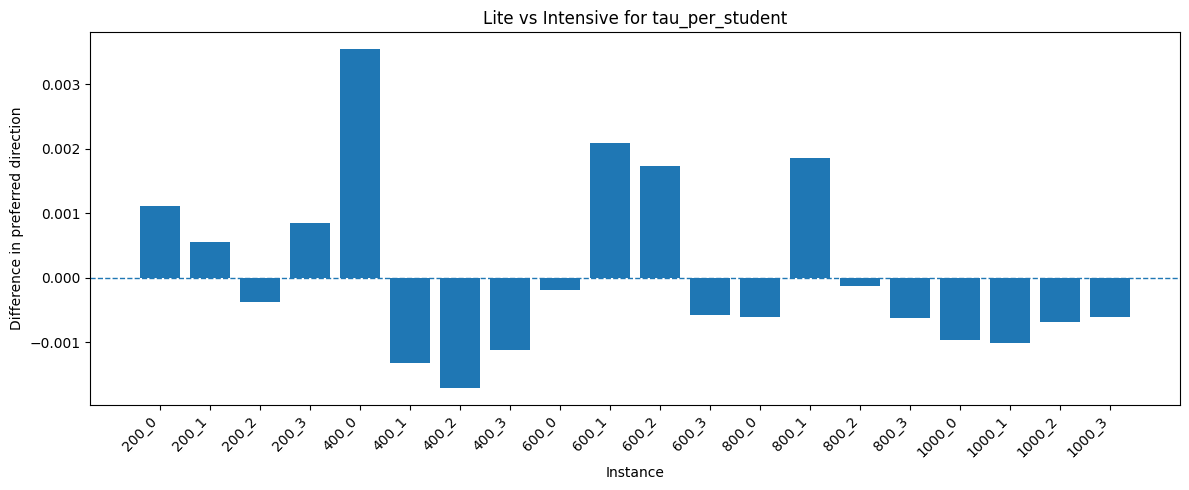

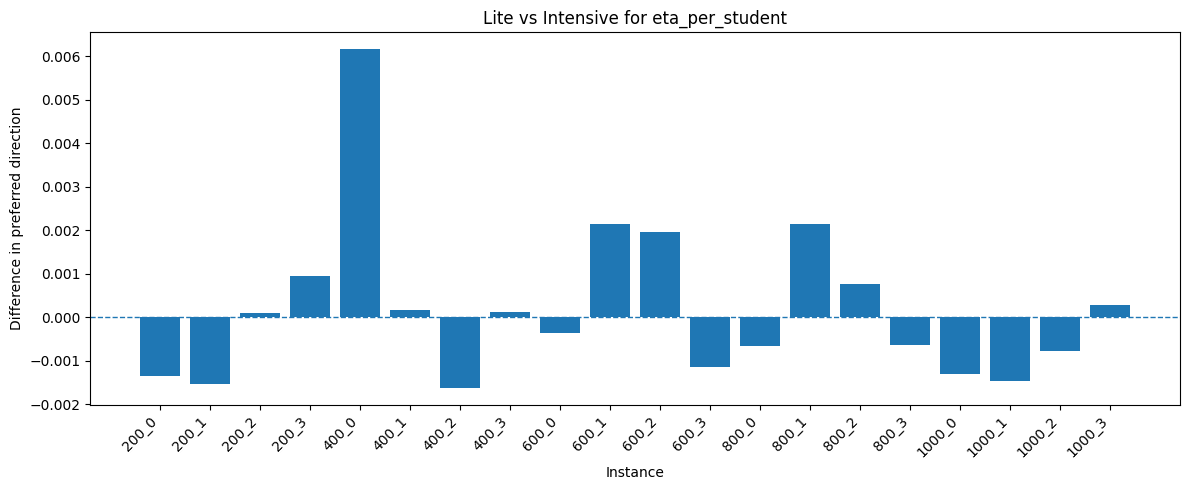

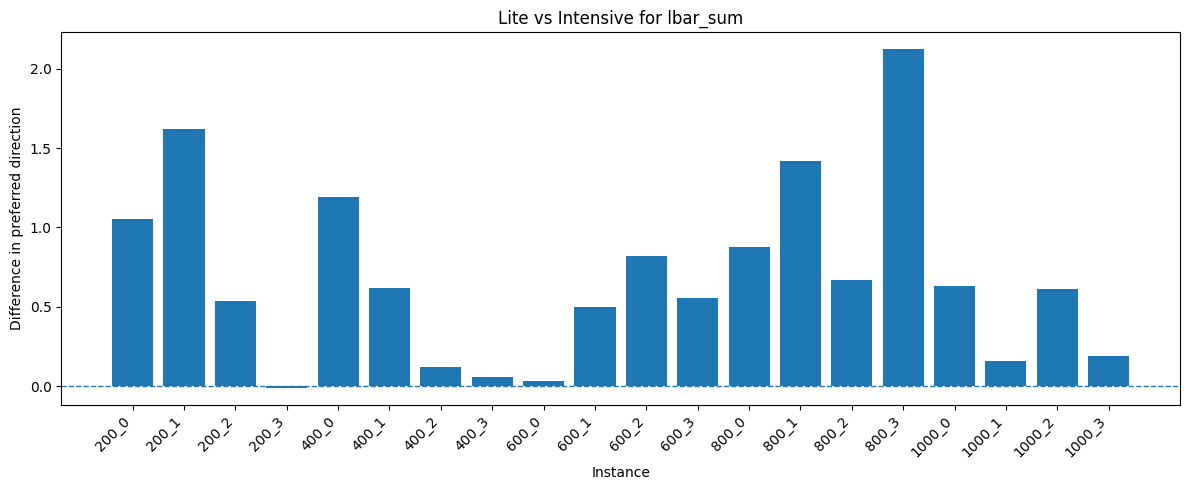

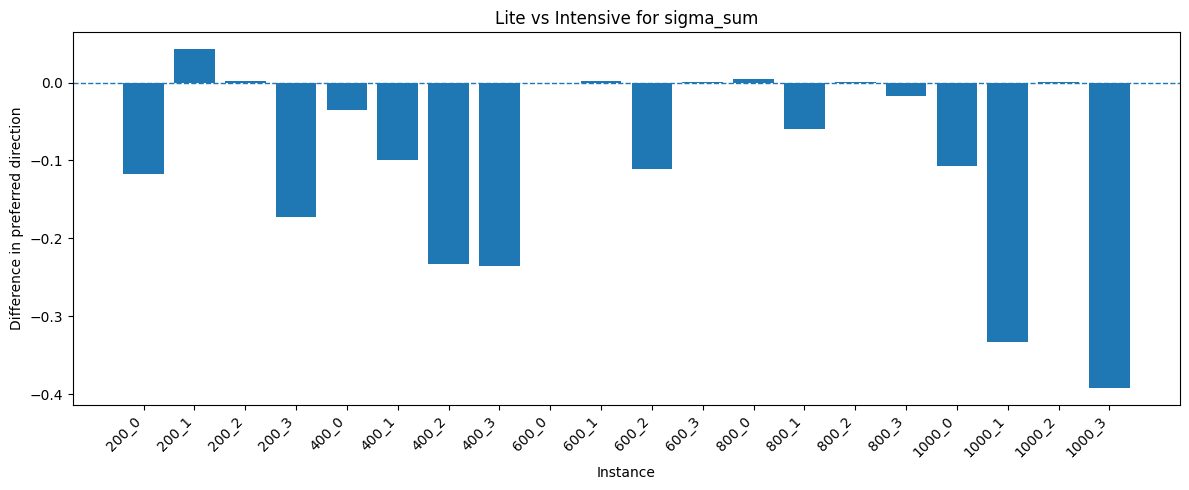

In [98]:
# ============================================================
# FIGURAS 6.5 — DIFERENCIAS POR OBJETIVO
# Valores positivos favorecen a Lite
# ============================================================

def make_instance_short_label(df):
    extracted_id = df["instance_clean"].astype(str).str.extract(r"_(\d+)$")[0]
    extracted_id = extracted_id.fillna(df["instance_clean"].astype(str))

    return df["n_students"].astype(str) + "_" + extracted_id.astype(str)


for cfg in objective_variant_config:
    obj = cfg["objective"]

    plot_df = objective_variant_instance[
        objective_variant_instance["objective"] == obj
    ].copy()

    plot_df["instance_short"] = make_instance_short_label(plot_df)

    plt.figure(figsize=(12, 5))

    plt.bar(
        plot_df["instance_short"],
        plot_df["diff_in_preferred_direction"]
    )

    plt.axhline(0, linestyle="--", linewidth=1)

    plt.xlabel("Instance")
    plt.ylabel("Difference in preferred direction")
    plt.title(f"Lite vs Intensive for {obj}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    filename = f"fig_6_5_lite_vs_intensive_{obj}.png"
    plt.savefig(OUTPUT_DIR / "6_5_Analysis_of_HH-LAP-SIPA_variants/" / filename, dpi=300)
    plt.show()

In [99]:
# ============================================================
# COSTE COMPUTACIONAL LITE VS INTENSIVE
# ============================================================

# Preferimos columnas de tiempo real medido, no columnas de presupuesto/límite.
preferred_runtime_cols = [
    "elapsed_seconds",
    "runtime_seconds",
    "wall_time_seconds",
    "duration_seconds",
]

runtime_col = None

for col in preferred_runtime_cols:
    if col in stats_all.columns and pd.api.types.is_numeric_dtype(stats_all[col]):
        runtime_col = col
        break

if runtime_col is None:
    runtime_candidates = []

    for col in stats_all.columns:
        col_lower = col.lower()

        if "limit" in col_lower:
            continue

        if any(keyword in col_lower for keyword in ["runtime", "elapsed", "wall", "seconds", "duration"]):
            if pd.api.types.is_numeric_dtype(stats_all[col]):
                runtime_candidates.append(col)

    print("Columnas candidatas de tiempo:", runtime_candidates)

    if len(runtime_candidates) > 0:
        runtime_col = runtime_candidates[0]

if runtime_col is None:
    print("No se ha encontrado ninguna columna numérica de tiempo real. Se omite el análisis de coste computacional.")
    variant_runtime_global = pd.DataFrame()
    variant_runtime_instance = pd.DataFrame()

else:
    print("Columna de tiempo utilizada:", runtime_col)

    stats_variants = stats_all[
        stats_all["algorithm_label"].isin(VARIANT_LABELS)
    ].copy()

    variant_runtime_instance = (
        stats_variants
        .groupby(["algorithm_label", "n_students", "instance_clean"], observed=True)
        .agg(
            mean_runtime=(runtime_col, "mean"),
            std_runtime=(runtime_col, "std"),
            n_runs=(runtime_col, "count"),
        )
        .reset_index()
    )

    variant_runtime_global = (
        stats_variants
        .groupby("algorithm_label", observed=True)
        .agg(
            mean_runtime=(runtime_col, "mean"),
            std_runtime=(runtime_col, "std"),
            median_runtime=(runtime_col, "median"),
            n_runs=(runtime_col, "count"),
        )
        .reset_index()
    )

    display(variant_runtime_instance)
    display(variant_runtime_global)

    variant_runtime_instance.to_csv(
        OUTPUT_DIR / "6_5_Analysis_of_HH-LAP-SIPA_variants/table_6_5_lite_vs_intensive_runtime_by_instance.csv",
        index=False
    )

    variant_runtime_global.to_csv(
        OUTPUT_DIR / "6_5_Analysis_of_HH-LAP-SIPA_variants/table_6_5_lite_vs_intensive_runtime_global.csv",
        index=False
    )

Columna de tiempo utilizada: elapsed_seconds


,algorithm_label,n_students,instance_clean,mean_runtime,std_runtime,n_runs
0,HH-LAP-SIPA-Intensive,200,problem_instance_ext_200_0,300.186771,0.094510,30
1,HH-LAP-SIPA-Intensive,200,problem_instance_ext_200_1,300.154847,0.094956,30
2,HH-LAP-SIPA-Intensive,200,problem_instance_ext_200_2,302.198129,2.401417,30
3,HH-LAP-SIPA-Intensive,200,problem_instance_ext_200_3,300.322429,0.210718,30
4,HH-LAP-SIPA-Intensive,400,problem_instance_ext_400_0,450.387053,0.257560,30
5,HH-LAP-SIPA-Intensive,400,problem_instance_ext_400_1,450.573401,0.320779,30
6,HH-LAP-SIPA-Intensive,400,problem_instance_ext_400_2,451.038112,0.508276,30
7,HH-LAP-SIPA-Intensive,400,problem_instance_ext_400_3,451.082680,0.546225,30
8,HH-LAP-SIPA-Intensive,600,problem_instance_ext_600_0,452.345303,1.803581,30
9,HH-LAP-SIPA-Intensive,600,problem_instance_ext_600_1,451.240779,0.607546,30


,algorithm_label,mean_runtime,std_runtime,median_runtime,n_runs
0,HH-LAP-SIPA-Intensive,481.472918,112.977469,451.472924,600
1,HH-LAP-SIPA-Lite,482.626551,114.140971,451.412812,600


In [100]:
# ============================================================
# TABLA COMPACTA 6.5
# ============================================================

variant_hv_global_tidy = (
    variant_hv_instance
    .groupby("algorithm_label", observed=True)
    .agg(
        mean_hv=("mean_hv", "mean"),
        std_hv=("mean_hv", "std"),
        n_instances=("instance_clean", "nunique"),
    )
    .reset_index()
)

variant_objective_tidy = objective_global_summary[
    objective_global_summary["algorithm_label"].isin(VARIANT_LABELS)
][[
    "algorithm_label",
    "mean_tau_per_student",
    "mean_eta_per_student",
    "mean_lbar_sum",
    "mean_sigma_sum",
    "mean_pareto_size",
]].copy()

table_6_5_variant_summary = variant_hv_global_tidy.merge(
    variant_objective_tidy,
    on="algorithm_label",
    how="left"
)

if "variant_runtime_global" in globals() and not variant_runtime_global.empty:
    table_6_5_variant_summary = table_6_5_variant_summary.merge(
        variant_runtime_global[[
            "algorithm_label",
            "mean_runtime",
            "std_runtime",
            "median_runtime",
        ]],
        on="algorithm_label",
        how="left"
    )

table_6_5_variant_summary = table_6_5_variant_summary.rename(columns={
    "algorithm_label": "Algorithm",
    "mean_hv": "Mean HV",
    "std_hv": "Std HV",
    "n_instances": "Instances",
    "mean_tau_per_student": "Tau/student",
    "mean_eta_per_student": "Eta/student",
    "mean_lbar_sum": "Lbar",
    "mean_sigma_sum": "Sigma",
    "mean_pareto_size": "Pareto size",
    "mean_runtime": "Mean runtime",
    "std_runtime": "Std runtime",
    "median_runtime": "Median runtime",
})

display(table_6_5_variant_summary)

,Algorithm,Mean HV,Std HV,Instances,Tau/student,Eta/student,Lbar,Sigma,Pareto size,Mean runtime,Std runtime,Median runtime
0,HH-LAP-SIPA-Intensive,0.360884,0.134517,20,0.780769,0.580643,2.119119,0.007381,110.113333,481.472918,112.977469,451.472924
1,HH-LAP-SIPA-Lite,0.571078,0.294158,20,0.780861,0.580840,1.430694,0.100277,42.083333,482.626551,114.140971,451.412812


In [101]:
table_6_5_variant_summary.to_csv(
    OUTPUT_DIR / "6_5_Analysis_of_HH-LAP-SIPA_variants/table_6_5_variant_summary.csv",
    index=False
)

## General discussion

In [102]:
# ============================================================
# 6.6 GENERAL DISCUSSION
# Tabla de hallazgos clave
# ============================================================

# Mejor algoritmo global por hypervolume
overall_hv_for_discussion = (
    hv_summary
    .groupby("algorithm_label", observed=True)
    .agg(
        mean_hv=("mean_hv", "mean"),
        std_hv=("mean_hv", "std"),
        n_instances=("instance_clean", "nunique"),
    )
    .reset_index()
    .sort_values("mean_hv", ascending=False)
)

best_overall_algorithm = overall_hv_for_discussion.iloc[0]["algorithm_label"]
best_overall_hv = overall_hv_for_discussion.iloc[0]["mean_hv"]

# Ganadores por instancia
instance_best_for_discussion = []

for (n_students, instance_clean), group in hv_summary.groupby(
    ["n_students", "instance_clean"],
    observed=True
):
    best_row = group.sort_values("mean_hv", ascending=False).iloc[0]

    instance_best_for_discussion.append({
        "n_students": n_students,
        "instance_clean": instance_clean,
        "best_algorithm": best_row["algorithm_label"],
        "best_hv": best_row["mean_hv"],
    })

instance_best_for_discussion = pd.DataFrame(instance_best_for_discussion)

proposed_wins = instance_best_for_discussion[
    instance_best_for_discussion["best_algorithm"].isin(VARIANT_LABELS)
].shape[0]

baseline_wins = instance_best_for_discussion[
    ~instance_best_for_discussion["best_algorithm"].isin(VARIANT_LABELS)
].shape[0]

# Mejor baseline global
baseline_labels = [
    label for label in LABEL_ORDER
    if label not in VARIANT_LABELS
]

best_baseline_row = overall_hv_for_discussion[
    overall_hv_for_discussion["algorithm_label"].isin(baseline_labels)
].iloc[0]

best_baseline_algorithm = best_baseline_row["algorithm_label"]
best_baseline_hv = best_baseline_row["mean_hv"]

# Mejor algoritmo por objetivo usando las columnas globales correctas
objective_discussion_config = [
    {
        "objective": "tau_per_student",
        "column": "mean_tau_per_student",
        "sense": "max"
    },
    {
        "objective": "eta_per_student",
        "column": "mean_eta_per_student",
        "sense": "max"
    },
    {
        "objective": "lbar_sum",
        "column": "mean_lbar_sum",
        "sense": "min"
    },
    {
        "objective": "sigma_sum",
        "column": "mean_sigma_sum",
        "sense": "min"
    },
]

objective_winners_for_discussion = []

for cfg in objective_discussion_config:
    obj = cfg["objective"]
    col = cfg["column"]
    sense = cfg["sense"]

    if sense == "max":
        best_row = objective_global_summary.sort_values(col, ascending=False).iloc[0]
    else:
        best_row = objective_global_summary.sort_values(col, ascending=True).iloc[0]

    objective_winners_for_discussion.append({
        "objective": obj,
        "sense": sense,
        "best_algorithm": best_row["algorithm_label"],
        "best_value": best_row[col],
    })

objective_winners_for_discussion = pd.DataFrame(objective_winners_for_discussion)

discussion_key_findings = pd.DataFrame([
    {
        "finding": "Total algorithms compared",
        "value": hv_summary["algorithm_label"].nunique()
    },
    {
        "finding": "Total instances analyzed",
        "value": hv_summary["instance_clean"].nunique()
    },
    {
        "finding": "Best overall algorithm by mean hypervolume",
        "value": best_overall_algorithm
    },
    {
        "finding": "Best overall mean hypervolume",
        "value": best_overall_hv
    },
    {
        "finding": "Best baseline algorithm by mean hypervolume",
        "value": best_baseline_algorithm
    },
    {
        "finding": "Best baseline mean hypervolume",
        "value": best_baseline_hv
    },
    {
        "finding": "Instances won by proposed HH-LAP-SIPA variants",
        "value": proposed_wins
    },
    {
        "finding": "Instances won by baselines",
        "value": baseline_wins
    },
    {
        "finding": "Lite wins over Intensive",
        "value": int(variant_hv_global["lite_wins"].iloc[0])
    },
    {
        "finding": "Intensive wins over Lite",
        "value": int(variant_hv_global["intensive_wins"].iloc[0])
    },
])

display(discussion_key_findings)
display(objective_winners_for_discussion)

,finding,value
0,Total algorithms compared,5
1,Total instances analyzed,20
2,Best overall algorithm by mean hypervolume,HH-LAP-SIPA-Lite
3,Best overall mean hypervolume,0.571078
4,Best baseline algorithm by mean hypervolume,GRASP
5,Best baseline mean hypervolume,0.099159
6,Instances won by proposed HH-LAP-SIPA variants,20
7,Instances won by baselines,0
8,Lite wins over Intensive,15
9,Intensive wins over Lite,5


,objective,sense,best_algorithm,best_value
0,tau_per_student,max,HH-LAP-SIPA-Lite,0.780861
1,eta_per_student,max,HH-LAP-SIPA-Lite,0.580840
2,lbar_sum,min,HH-LAP-SIPA-Lite,1.430694
3,sigma_sum,min,HH-LAP-SIPA-Intensive,0.007381


In [103]:
discussion_key_findings.to_csv(
    OUTPUT_DIR / "6_6_General_discussion/table_6_6_discussion_key_findings.csv",
    index=False
)

objective_winners_for_discussion.to_csv(
    OUTPUT_DIR / "6_6_General_discussion/table_6_6_objective_winners.csv",
    index=False
)

In [104]:
# ============================================================
# TABLA FINAL DE RANKING GLOBAL
# ============================================================

final_ranking_table = overall_hv_for_discussion.copy()

final_ranking_table["rank"] = final_ranking_table["mean_hv"].rank(
    ascending=False,
    method="min"
).astype(int)

final_ranking_table = final_ranking_table[[
    "rank",
    "algorithm_label",
    "mean_hv",
    "std_hv",
    "n_instances",
]].sort_values("rank")

final_ranking_table = final_ranking_table.rename(columns={
    "rank": "Rank",
    "algorithm_label": "Algorithm",
    "mean_hv": "Mean HV",
    "std_hv": "Std HV",
    "n_instances": "Instances",
})

display(final_ranking_table)

,Rank,Algorithm,Mean HV,Std HV,Instances
2,1,HH-LAP-SIPA-Lite,0.571078,0.294158,20
1,2,HH-LAP-SIPA-Intensive,0.360884,0.134517,20
0,3,GRASP,0.099159,0.180784,20
3,4,NSGA-III,0.037247,0.027202,20
4,5,Random,0.018364,0.005740,20


In [105]:
final_ranking_table.to_csv(
    OUTPUT_DIR / "6_6_General_discussion/table_6_6_final_global_ranking.csv",
    index=False
)

In [106]:
# ============================================================
# LISTADO FINAL DE ARCHIVOS GENERADOS
# ============================================================

generated_files = sorted(OUTPUT_DIR.glob("*"))

generated_files_df = pd.DataFrame({
    "file": [file.name for file in generated_files],
    "path": [str(file) for file in generated_files],
    "suffix": [file.suffix for file in generated_files],
})

display(generated_files_df)

,file,path,suffix
0,6_1_Overall_hypervolume_comparison,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,
1,6_2_Hypervolume_by_instance_size,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,
2,6_3_Instance_level_variability,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,
3,6_4_Per_objective_performance_analysis,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,
4,6_5_Analysis_of_HH-LAP-SIPA_variants,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,
5,6_6_General_discussion,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,


In [107]:
generated_files_df.to_csv(
    OUTPUT_DIR / "6_6_General_discussion/generated_analysis_files.csv",
    index=False
)